# 01 · Exploratory Data Analysis: Predict Future Sales

**Curso:** Product Development, Proyecto #1
**Autor:** Fabio Suruy
**Dataset:** [Predict Future Sales (Kaggle)](https://www.kaggle.com/competitions/competitive-data-science-predict-future-sales/data). Ventas diarias de la cadena rusa de retail **1C Company**, de enero 2013 a octubre 2015.

**Objetivo de negocio:** predecir las unidades vendidas en el mes (`item_cnt_month`) para cada par **tienda-producto** de `test.csv` en **noviembre 2015**. Este EDA entiende los datos, define la limpieza y deja identificados los patrones que usará el modelo de forecasting.

### Contenido
1. Configuración y carga de datos
2. Comprensión inicial del dataset
3. Validación de la estructura de los datos
4. Análisis de valores faltantes y duplicados
5. Análisis descriptivo general
6. Exploración temporal
7. Análisis comparativo entre sucursales y productos
8. Visualizaciones clave
9. Autocorrelación (ACF) y autocorrelación parcial (PACF)
10. Insights y conclusiones

> Las funciones reutilizables (carga, limpieza, agregación mensual y ACF/PACF) viven en `predict_future_sales/eda.py`, así el notebook queda legible y la fase 2 del curso parte de código modular.

## 1. Configuración y carga de datos
Las rutas salen de `predict_future_sales.config` (estructura cookiecutter); no hay rutas absolutas en el notebook.

In [1]:
import warnings

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller

from predict_future_sales import eda
from predict_future_sales.config import INTERIM_DATA_DIR, RAW_DATA_DIR

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (13, 4.5)
plt.rcParams["axes.titleweight"] = "bold"
thousands = mtick.FuncFormatter(lambda x, _: f"{x:,.0f}")

print("Datos crudos en:", RAW_DATA_DIR)

2026-11-14 17:08:52.102 -06:00 | INFO     | predict_future_sales.config:<module>:11 - PROJ_ROOT path is: C:\Users\20180\Desktop\Documento 21-8-25\Maestria\8vo Trimestre\Product Development\Proyectos\predict-future-sales


Datos crudos en: C:\Users\20180\Desktop\Documento 21-8-25\Maestria\8vo Trimestre\Product Development\Proyectos\predict-future-sales\data\raw


In [2]:
raw = eda.load_raw()
sales, items, categories, shops, test = (raw[k] for k in
                                         ["sales_train", "items", "item_categories", "shops", "test"])

## 2. Comprensión inicial del dataset

### 2.a Primeras filas de cada archivo

In [3]:
for name, df in raw.items():
    print(f"\n=== {name} ===")
    display(df.head())


=== sales_train ===


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
0,02.01.2013,0,59,22154,999.00,1.00
1,03.01.2013,0,25,2552,899.00,1.00
2,05.01.2013,0,25,2552,899.00,-1.00
3,06.01.2013,0,25,2554,"1,709.05",1.00
4,15.01.2013,0,25,2555,"1,099.00",1.00



=== items ===


,item_name,item_id,item_category_id
0,! ВО ВЛАСТИ НАВАЖДЕНИЯ (ПЛАСТ.) D,0,40
1,!ABBYY FineReader 12 Professional Edition Full...,1,76
2,***В ЛУЧАХ СЛАВЫ (UNV) D,2,40
3,***ГОЛУБАЯ ВОЛНА (Univ) D,3,40
4,***КОРОБКА (СТЕКЛО) D,4,40



=== item_categories ===


,item_category_name,item_category_id
0,PC - Гарнитуры/Наушники,0
1,Аксессуары - PS2,1
2,Аксессуары - PS3,2
3,Аксессуары - PS4,3
4,Аксессуары - PSP,4



=== shops ===


,shop_name,shop_id
0,"!Якутск Орджоникидзе, 56 фран",0
1,"!Якутск ТЦ ""Центральный"" фран",1
2,"Адыгея ТЦ ""Мега""",2
3,"Балашиха ТРК ""Октябрь-Киномир""",3
4,"Волжский ТЦ ""Волга Молл""",4



=== test ===


,ID,shop_id,item_id
0,0,5,5037
1,1,5,5320
2,2,5,5233
3,3,5,5232
4,4,5,5268


### 2.b Tamaño de cada tabla

In [4]:
sizes = pd.DataFrame(
    {name: {"filas": df.shape[0], "columnas": df.shape[1],
            "memoria_MB": df.memory_usage(deep=True).sum() / 1024**2}
     for name, df in raw.items()}
).T
sizes

,filas,columnas,memoria_MB
sales_train,"2,935,849.00",6.00,162.39
items,"22,170.00",3.00,1.79
item_categories,84.00,2.00,0.00
shops,60.00,2.00,0.00
test,"214,200.00",3.00,4.90


`sales_train` es la tabla de hechos, con ~2.9 millones de transacciones diarias. Las otras tres son catálogos pequeños (22,170 productos, 84 categorías y 60 tiendas). `test` tiene 214,200 pares tienda-producto: **42 tiendas × 5,100 productos**, es decir, una malla completa. Eso tiene una implicación fuerte que veremos en la sección 10.

### 2.c Diccionario de columnas y variable objetivo

| Columna | Tabla | Tipo | Descripción |
|---|---|---|---|
| `date` | sales_train | fecha | Día de la transacción (texto `dd.mm.aaaa` en el archivo original) |
| `date_block_num` | sales_train | entero (ordinal) | Número de mes consecutivo: 0 = ene-2013 … 33 = oct-2015 |
| `shop_id` | sales_train, shops, test | categórica (ID) | Identificador de la tienda |
| `item_id` | sales_train, items, test | categórica (ID) | Identificador del producto |
| `item_price` | sales_train | numérica continua | Precio unitario del producto en esa transacción (rublos) |
| `item_cnt_day` | sales_train | numérica discreta | Unidades vendidas en el día; los valores negativos son devoluciones |
| `item_name` | items | texto | Nombre del producto (en ruso) |
| `item_category_id` | items, item_categories | categórica (ID) | Categoría del producto |
| `item_category_name` | item_categories | texto | Nombre de la categoría, con formato `Grupo - Subgrupo` (p. ej. `Игры - PS3` = Juegos - PS3) |
| `shop_name` | shops | texto | Nombre de la tienda; la primera palabra es la ciudad |
| `ID` | test | entero | Identificador de cada par (tienda, producto) a predecir |

**Variable objetivo:** `item_cnt_month`, que es la **suma mensual de `item_cnt_day`** por par tienda-producto (Kaggle además la recorta al rango [0, 20]). En el EDA trabajamos con `item_cnt_day` y con sus agregaciones mensuales.

**Variable derivada:** `revenue = item_price × item_cnt_day` (ingresos), porque el dataset no trae ventas en dinero.

### 2.d Rango temporal

In [5]:
dates = pd.to_datetime(sales["date"], format="%d.%m.%Y")
print(f"Fecha mínima : {dates.min():%d-%m-%Y}")
print(f"Fecha máxima : {dates.max():%d-%m-%Y}")
print(f"Días cubiertos: {(dates.max() - dates.min()).days + 1:,}")
print(f"Meses (date_block_num únicos): {sales['date_block_num'].nunique()}  "
      f"(de {sales['date_block_num'].min()} a {sales['date_block_num'].max()})")

Fecha mínima : 01-01-2013
Fecha máxima : 31-10-2015
Días cubiertos: 1,034
Meses (date_block_num únicos): 34  (de 0 a 33)


Los datos van del **1 de enero de 2013 al 31 de octubre de 2015**: 1,034 días, o sea **34 meses** (bloques 0 a 33). El mes a predecir, noviembre 2015, equivale a `date_block_num = 34`. Como 2015 solo trae 10 meses, las comparaciones entre años deben hacerse sobre periodos equivalentes (enero–octubre).

## 3. Validación de la estructura de los datos

### 3.a Tipos de datos

In [6]:
dtypes = pd.concat(
    {name: df.dtypes.astype(str) for name, df in raw.items()}, names=["tabla", "columna"]
).rename("dtype").to_frame()
dtypes

dtype
tabla           columna                    
sales_train     date                    str
                date_block_num        int64
                shop_id               int64
                item_id               int64
                item_price          float64
                item_cnt_day        float64
items           item_name               str
                item_id               int64
                item_category_id      int64
item_categories item_category_name      str
                item_category_id      int64
shops           shop_name               str
                shop_id               int64
test            ID                    int64
                shop_id               int64
                item_id               int64

- `date` viene como **texto** (`object`/`str`) y hay que convertirla a `datetime`.
- `shop_id`, `item_id` e `item_category_id` vienen como enteros, pero **son categóricas**: son identificadores y no tiene sentido promediarlos.
- `item_cnt_day` viene como `float64` aunque representa unidades enteras. Se conserva así porque sumarla no cambia nada y facilita la agregación.
- `item_price` es numérica continua.

### 3.b Conversión de `date` a datetime

In [7]:
df = eda.build_sales_table(sales, items, categories, shops)   # convierte fecha + revenue + catálogos
print(df["date"].dtype)
df[["date", "date_block_num", "shop_id", "item_id", "item_price", "item_cnt_day",
    "revenue", "item_category_id", "category_group", "city"]].head()

datetime64[us]


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day,revenue,item_category_id,category_group,city
0,2013-01-02,0,59,22154,999.00,1.00,999.00,37,Cine,Ярославль
1,2013-01-03,0,25,2552,899.00,1.00,899.00,58,Música,Москва
2,2013-01-05,0,25,2552,899.00,-1.00,-899.00,58,Música,Москва
3,2013-01-06,0,25,2554,"1,709.05",1.00,"1,709.05",58,Música,Москва
4,2013-01-15,0,25,2555,"1,099.00",1.00,"1,099.00",56,Música,Москва


La conversión con `format="%d.%m.%Y"` funcionó sin errores, así que **todas** las fechas tenían el formato esperado. De paso se unieron los catálogos y se crearon:
- `revenue` (ingresos)
- `category_group`: grupo principal de la categoría, traducido al español
- `city`: ciudad de la tienda

### 3.c Frecuencia temporal y consistencia de `date_block_num`

In [8]:
all_days = pd.date_range(df["date"].min(), df["date"].max(), freq="D")
days_with_sales = df["date"].nunique()
print(f"Días en el calendario: {len(all_days):,} | días con ventas: {days_with_sales:,} | "
      f"días sin ventas: {len(all_days) - days_with_sales}")

expected_block = (df["date"].dt.year - 2013) * 12 + df["date"].dt.month - 1
print(f"Filas donde date_block_num no coincide con la fecha: "
      f"{(expected_block != df['date_block_num']).sum()}")

daily_rows = df.groupby("date").size()
print(f"Transacciones por día · mínimo {daily_rows.min():,} · mediana {daily_rows.median():,.0f} · "
      f"máximo {daily_rows.max():,}")

Días en el calendario: 1,034 | días con ventas: 1,034 | días sin ventas: 0
Filas donde date_block_num no coincide con la fecha: 0
Transacciones por día · mínimo 1,123 · mediana 2,590 · máximo 9,434


In [9]:
# A nivel par tienda-producto la serie diaria es muy dispersa
pair_days = df.groupby(["shop_id", "item_id"])["date"].nunique()
pair_months = df.groupby(["shop_id", "item_id"])["date_block_num"].nunique()
print(f"Pares tienda-producto distintos: {len(pair_days):,}")
print(f"Mediana de días con venta por par: {pair_days.median():.0f} de 1,034")
print(f"Mediana de meses con venta por par: {pair_months.median():.0f} de 34")

Pares tienda-producto distintos: 424,124
Mediana de días con venta por par: 3 de 1,034
Mediana de meses con venta por par: 2 de 34


**Conclusiones de frecuencia**
- **No hay días sin ventas** a nivel de toda la cadena: los 1,034 días del calendario tienen transacciones.
- `date_block_num` es **100 % consistente** con la fecha.
- A nivel **par tienda-producto** los datos son muy dispersos: la mediana es de pocos días con venta en casi tres años. Cada fila es "un producto vendido en una tienda en un día", y los días sin venta simplemente no aparecen como filas.

**Frecuencia recomendada: mensual.**
1. Es la granularidad del objetivo (`item_cnt_month`).
2. Reduce el ruido y la dispersión diaria.
3. Deja 34 observaciones por serie, suficientes para ver tendencia y una estacionalidad anual.

La serie diaria total se usa solo para estudiar el ciclo semanal (sección 6). La semanal no aporta mucho más, porque las semanas cruzan los límites de mes y el objetivo es mensual.

## 4. Análisis de valores faltantes y duplicados

### 4.a Valores nulos

In [10]:
nulls = pd.concat(
    {name: pd.DataFrame({"nulos": d.isna().sum(), "%": d.isna().mean() * 100})
     for name, d in raw.items()}, names=["tabla", "columna"])
print(f"Total de nulos en todo el dataset: {int(nulls['nulos'].sum())}")
nulls

Total de nulos en todo el dataset: 0


nulos    %
tabla           columna                       
sales_train     date                    0 0.00
                date_block_num          0 0.00
                shop_id                 0 0.00
                item_id                 0 0.00
                item_price              0 0.00
                item_cnt_day            0 0.00
items           item_name               0 0.00
                item_id                 0 0.00
                item_category_id        0 0.00
item_categories item_category_name      0 0.00
                item_category_id        0 0.00
shops           shop_name               0 0.00
                shop_id                 0 0.00
test            ID                      0 0.00
                shop_id                 0 0.00
                item_id                 0 0.00

**Ninguna tabla tiene valores nulos** (0 %), así que no hace falta eliminar ni imputar por faltantes. Pero la calidad no se reduce a los nulos: hay valores **inválidos** que sí están presentes. Los revisamos a continuación.

### 4.b Valores inválidos y estrategia de tratamiento

In [11]:
neg_price = df[df["item_price"] <= 0]
returns = df[df["item_cnt_day"] < 0]
print(f"Precios <= 0          : {len(neg_price)} fila(s)")
display(neg_price[["date", "shop_id", "item_id", "item_price", "item_cnt_day"]])
print(f"Cantidades negativas  : {len(returns):,} filas ({len(returns) / len(df):.2%} del total) "
      f"= {-returns['item_cnt_day'].sum():,.0f} unidades devueltas")
print(f"Cantidades = 0        : {(df['item_cnt_day'] == 0).sum()}")

Precios <= 0          : 1 fila(s)


,date,shop_id,item_id,item_price,item_cnt_day
484683,2013-05-15,32,2973,-1.00,1.00


Cantidades negativas  : 7,356 filas (0.25% del total) = 7,541 unidades devueltas
Cantidades = 0        : 0


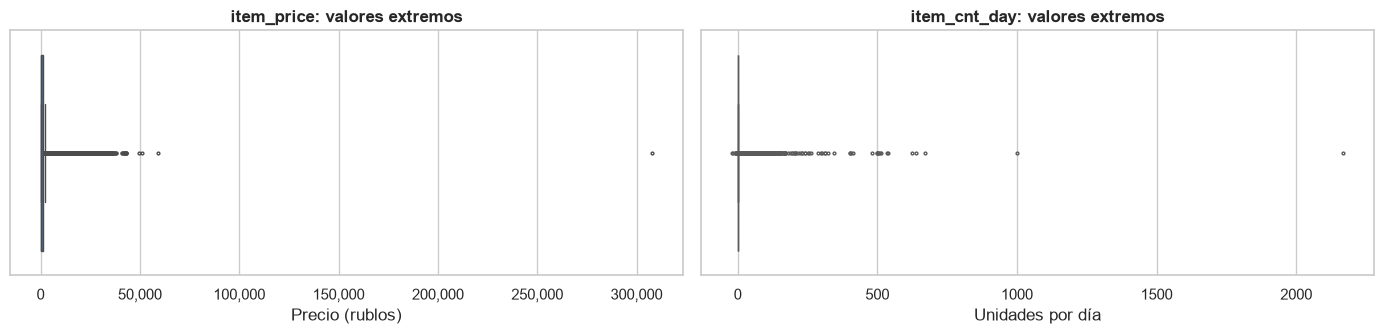

Transacciones más extremas:


,date,shop_id,item_id,item_price,item_cnt_day
1163158,2013-12-13,12,6066,"307,980.00",1.00
885138,2013-09-17,12,11365,"59,200.00",1.00
1488135,2014-03-20,25,13199,"50,999.00",1.00


,date,shop_id,item_id,item_price,item_cnt_day
2909818,2015-10-28,12,11373,0.91,"2,169.00"
2326930,2015-01-15,12,20949,4.00,"1,000.00"
2864235,2015-09-30,12,9248,"1,692.53",669.00


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
sns.boxplot(x=df["item_price"], ax=axes[0], color="#4C72B0", fliersize=2)
axes[0].set(title="item_price: valores extremos", xlabel="Precio (rublos)")
axes[0].xaxis.set_major_formatter(thousands)
sns.boxplot(x=df["item_cnt_day"], ax=axes[1], color="#DD8452", fliersize=2)
axes[1].set(title="item_cnt_day: valores extremos", xlabel="Unidades por día")
plt.tight_layout()
plt.show()

print("Transacciones más extremas:")
display(df.nlargest(3, "item_price")[["date", "shop_id", "item_id", "item_price", "item_cnt_day"]])
display(df.nlargest(3, "item_cnt_day")[["date", "shop_id", "item_id", "item_price", "item_cnt_day"]])

**Estrategia de tratamiento**

| Problema | Hallazgo | Decisión | Justificación |
|---|---|---|---|
| Nulos | 0 | Ninguna acción | No existen |
| `item_price <= 0` | 1 fila (precio = −1) | **Eliminar** | Es un error de captura y una sola fila no afecta el análisis |
| `item_cnt_day < 0` | ~7,350 filas (0.25 %) | **Conservar** | Son devoluciones reales; el objetivo mensual es *neto* (ventas − devoluciones) |
| `item_price` extremo | 1 fila a 307,980 rublos, ~5× el siguiente precio | **Eliminar** (precio > 100,000) | Es un único registro inconsistente con el resto del catálogo |
| `item_cnt_day` extremo | 1 fila con 2,169 unidades a ~0.9 rublos | **Eliminar** (cantidad > 1,000) | Combina cantidad y precio anómalos (posible carga masiva en la tienda online) |

El resto de valores altos (cientos de unidades) son ventas masivas reales, sobre todo en la tienda online `12`. No se eliminan, se analizan en la sección 7.c.

### 4.c Registros duplicados y tiendas repetidas

In [13]:
exact_dups = df[df.duplicated(keep=False)]
print(f"Duplicados exactos: {df.duplicated().sum()} filas a eliminar")
display(exact_dups[["date", "shop_id", "item_id", "item_price", "item_cnt_day"]].head(12))
print(f"Filas que repiten (fecha, tienda, producto) con otro precio o cantidad: "
      f"{df.duplicated(['date', 'shop_id', 'item_id']).sum() - df.duplicated().sum()}")

Duplicados exactos: 6 filas a eliminar


,date,shop_id,item_id,item_price,item_cnt_day
76961,2013-01-05,54,20130,149.00,1.00
76962,2013-01-05,54,20130,149.00,1.00
1435365,2014-02-23,50,3423,999.00,1.00
1435367,2014-02-23,50,3423,999.00,1.00
1496765,2014-03-23,21,3423,999.00,1.00
1496766,2014-03-23,21,3423,999.00,1.00
1671872,2014-05-01,50,3423,999.00,1.00
1671873,2014-05-01,50,3423,999.00,1.00
1866322,2014-07-12,25,3423,999.00,1.00
1866340,2014-07-12,25,3423,999.00,1.00


Filas que repiten (fecha, tienda, producto) con otro precio o cantidad: 22


Hay **6 filas idénticas** en todas las columnas. Como cada fila ya agrega un producto-tienda-día, una fila repetida es casi con seguridad un doble registro, así que **se elimina**. Las pocas filas que repiten fecha-tienda-producto con *otro* precio sí son válidas (por ejemplo, un cambio de precio en el mismo día) y se conservan.

Ahora revisamos `shops.csv` en busca de tiendas con el mismo nombre y distinto ID:

In [14]:
shop_activity = (df.groupby("shop_id")["date_block_num"].agg(["min", "max", "nunique"])
                   .rename(columns={"min": "primer_mes", "max": "ultimo_mes", "nunique": "meses_activos"}))
pairs = [(0, 57), (1, 58), (11, 10), (40, 39)]
check = pd.concat([shops.set_index("shop_id").loc[[a, b]].join(shop_activity) for a, b in pairs])
check["en_test"] = check.index.isin(test["shop_id"])
check

,shop_name,primer_mes,ultimo_mes,meses_activos,en_test
shop_id,,,,,
0,"!Якутск Орджоникидзе, 56 фран",0,1,2,False
57,"Якутск Орджоникидзе, 56",2,33,32,True
1,"!Якутск ТЦ ""Центральный"" фран",0,1,2,False
58,"Якутск ТЦ ""Центральный""",2,33,32,True
11,Жуковский ул. Чкалова 39м²,25,25,1,False
10,Жуковский ул. Чкалова 39м?,0,33,33,True
40,"РостовНаДону ТРК ""Мегацентр Горизонт"" Островной",14,24,11,False
39,"РостовНаДону ТРК ""Мегацентр Горизонт""",14,33,20,True


| IDs | Nombre | Evidencia | Decisión |
|---|---|---|---|
| 0 → 57 | Якутск Орджоникидзе, 56 (el 0 lleva "фран" = franquicia) | El 0 vende en los meses 0–1 y el 57 desde el mes 2: no se traslapan | **Unificar en 57** |
| 1 → 58 | Якутск ТЦ "Центральный" | El mismo patrón: el 1 vende en los meses 0–1 y el 58 desde el mes 2 | **Unificar en 58** |
| 11 → 10 | Жуковский ул. Чкалова 39м² (el 10 tiene un `?` por error de codificación) | El 11 solo vende en el mes 25, justo el único mes que le falta al 10 | **Unificar en 10** |
| 40 vs 39 | РостовНаДону "Мегацентр Горизонт" (el 40 agrega "Островной") | Vendieron **al mismo tiempo** (meses 14–24) | **No unificar**: son pabellones distintos del mismo centro comercial |

Las tiendas 57, 58 y 10 están en `test`, mientras que 0, 1 y 11 no. Unificarlas le da a esas tiendas el historial completo para el forecasting.

In [15]:
df, cleaning_report = eda.clean_sales(df)
display(pd.Series(cleaning_report, name="filas").to_frame())

INTERIM_DATA_DIR.mkdir(parents=True, exist_ok=True)
df.to_parquet(INTERIM_DATA_DIR / "sales_clean.parquet", index=False)
print("Guardado:", INTERIM_DATA_DIR / "sales_clean.parquet")

,filas
filas_iniciales,2935849
duplicados_eliminados,6
precio_no_positivo_eliminados,1
outliers_extremos_eliminados,2
filas_con_tienda_reasignada,16034
filas_finales,2935840


Guardado: C:\Users\20180\Desktop\Documento 21-8-25\Maestria\8vo Trimestre\Product Development\Proyectos\predict-future-sales\data\interim\sales_clean.parquet


La limpieza eliminó solo 9 filas (0.0003 %) y reasignó las ventas de las 3 tiendas duplicadas. El resultado se guarda en `data/interim/sales_clean.parquet` (no versionado), que es la base de las secciones siguientes y de la etapa de feature engineering. **Desde aquí, `df` es el dataset limpio.**

## 5. Análisis descriptivo general

### 5.a Estadísticas de `item_price`, `item_cnt_day` e ingresos

In [16]:
stats = df[["item_price", "item_cnt_day", "revenue"]].agg(
    ["mean", "median", "min", "max", "std"]).T
stats.columns = ["media", "mediana", "mínimo", "máximo", "desv_std"]
stats["coef_variación"] = stats["desv_std"] / stats["media"]
stats

,media,mediana,mínimo,máximo,desv_std,coef_variación
item_price,890.75,399.00,0.07,"59,200.00","1,720.49",1.93
item_cnt_day,1.24,1.00,-22.00,"1,000.00",2.29,1.85
revenue,"1,157.63",449.00,"-68,970.00","1,829,990.00","5,680.79",4.91


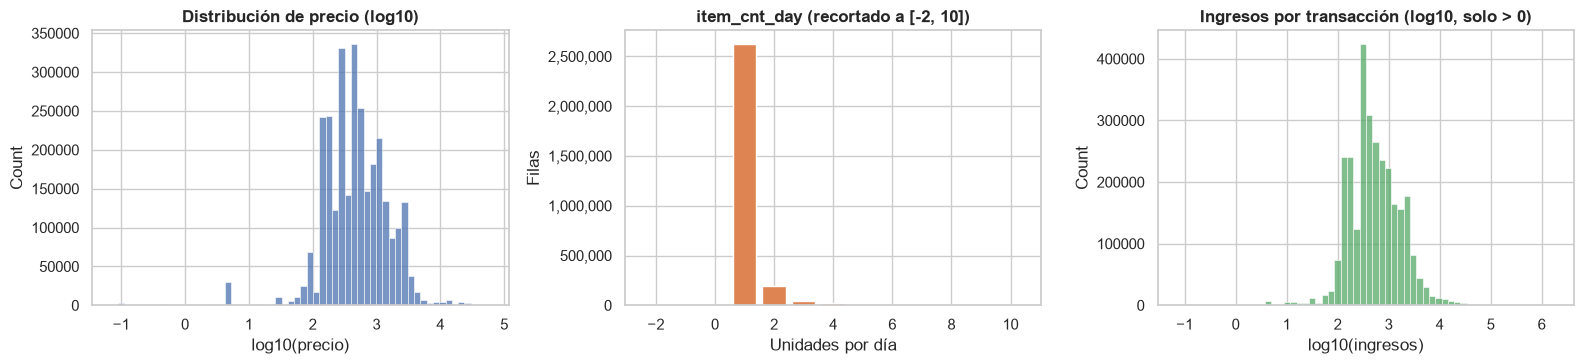

Filas con item_cnt_day = 1: 89.6%


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
sns.histplot(np.log10(df.loc[df["item_price"] > 0, "item_price"]), bins=60, ax=axes[0])
axes[0].set(title="Distribución de precio (log10)", xlabel="log10(precio)")
counts = df["item_cnt_day"].clip(-2, 10).value_counts().sort_index()
axes[1].bar(counts.index, counts.values, color="#DD8452")
axes[1].set(title="item_cnt_day (recortado a [-2, 10])", xlabel="Unidades por día", ylabel="Filas")
axes[1].yaxis.set_major_formatter(thousands)
sns.histplot(np.log10(df.loc[df["revenue"] > 0, "revenue"]), bins=60, ax=axes[2], color="#55A868")
axes[2].set(title="Ingresos por transacción (log10, solo > 0)", xlabel="log10(ingresos)")
plt.tight_layout()
plt.show()
print(f"Filas con item_cnt_day = 1: {(df['item_cnt_day'] == 1).mean():.1%}")

- **`item_price`**: media ≈ 890 contra mediana ≈ 399 rublos, una **asimetría positiva** fuerte (cola de consolas y ediciones especiales). En escala logarítmica la distribución es aproximadamente normal con varios modos, que corresponden a los precios típicos de cada tipo de producto.
- **`item_cnt_day`**: la mediana es 1 y la gran mayoría de las filas (~90 %) son exactamente 1 unidad. La desviación estándar es mucho mayor que la media por las ventas masivas ocasionales: es una distribución de conteo **muy concentrada en valores bajos con cola larga**.
- **Ingresos**: heredan la asimetría del precio, con media mucho mayor que la mediana. Para modelar conviene trabajar con transformaciones logarítmicas o con estadísticos robustos (mediana).

### 5.b.i Distribución por producto y categoría

In [18]:
by_item = df.groupby("item_id")["item_cnt_day"].sum()
print(f"Productos con ventas: {by_item.size:,} de {items.shape[0]:,} en el catálogo")
print(by_item.describe(percentiles=[.25, .5, .75, .9, .99]).to_string())

share = by_item.sort_values(ascending=False).cumsum() / by_item.sum()
top_pct = (share <= 0.8).mean()
print(f"\nEl {top_pct:.1%} de los productos concentra el 80 % de las unidades vendidas")

Productos con ventas: 21,806 de 22,170 en el catálogo
count    21,806.00
mean        167.20
std       1,365.86
min         -11.00
25%           7.00
50%          33.00
75%         124.00
90%         360.00
99%       1,991.80
max     187,642.00

El 17.8% de los productos concentra el 80 % de las unidades vendidas


In [19]:
by_group = (df.groupby("category_group")
              .agg(unidades=("item_cnt_day", "sum"), ingresos=("revenue", "sum"),
                   productos=("item_id", "nunique"))
              .sort_values("unidades", ascending=False))
by_group["% unidades"] = by_group["unidades"] / by_group["unidades"].sum() * 100
by_group["% ingresos"] = by_group["ingresos"] / by_group["ingresos"].sum() * 100
by_group

,unidades,ingresos,productos,% unidades,% ingresos
category_group,,,,,
Cine,"916,941.00","334,987,320.19",7390,25.15,9.86
Juegos PC,"689,106.00","477,987,109.75",2136,18.90,14.06
Juegos consola,"646,769.00","1,153,842,672.55",1732,17.74,33.95
Regalos,"584,366.00","309,146,571.48",3461,16.03,9.10
Música,"411,294.00","149,719,998.79",4259,11.28,4.41
Accesorios,"85,056.00","166,386,781.45",217,2.33,4.90
Libros,"76,341.00","30,348,897.24",1229,2.09,0.89
Programas,"74,953.00","122,082,915.13",1133,2.06,3.59
Tarjetas de pago,"53,883.00","72,953,095.72",41,1.48,2.15


- **Distribución de cola larga (Pareto):** solo el **~18 %** de los productos concentra el 80 % de las unidades; la mediana es de 33 unidades por producto en casi 3 años, mientras que la mayoría de los ~21,800 productos con ventas vende muy pocas unidades en casi 3 años.
- **Por grupo de categoría:**
  - **Cine, Juegos (consola y PC) y Música** dominan el volumen.
  - **Juegos y Consolas** pesan mucho más en *ingresos* que en unidades, por su precio alto.
  - **Cine y Música** son volumen de bajo precio.
- Esto sugiere que la **categoría** es una variable clave para el modelo, porque resume precio y comportamiento de demanda.

### 5.b.ii Distribución por sucursal

In [20]:
by_shop = (df.groupby(["shop_id", "city"])
             .agg(unidades=("item_cnt_day", "sum"), ingresos=("revenue", "sum"),
                  meses_activos=("date_block_num", "nunique"))
             .sort_values("unidades", ascending=False))
by_shop["unidades_por_mes"] = by_shop["unidades"] / by_shop["meses_activos"]
print(by_shop["unidades"].describe().to_string())
by_shop.head(10)

count        57.00
mean     63,965.42
std      58,413.29
min         330.00
25%      25,838.00
50%      53,886.00
75%      71,201.00
max     310,777.00


,,unidades,ingresos,meses_activos,unidades_por_mes
shop_id,city,,,,
31,Москва,"310,777.00","235,217,019.05",34,"9,140.50"
25,Москва,"241,919.00","216,479,572.44",34,"7,115.26"
54,Химки,"185,789.00","141,939,524.00",28,"6,635.32"
28,Москва,"184,557.00","159,746,337.38",34,"5,428.15"
57,Якутск,"152,812.00","119,637,153.53",34,"4,494.47"
42,СПб,"144,933.00","151,916,533.55",34,"4,262.74"
27,Москва,"136,657.00","140,632,474.12",32,"4,270.53"
6,Воронеж,"100,489.00","98,067,453.80",34,"2,955.56"
58,Якутск,"88,045.00","71,975,824.83",34,"2,589.56"


Las ventas por tienda son **muy desiguales**: unas pocas tiendas grandes (Moscú, como la `31` y la `25`) venden varias veces más que la mediana. Además, varias tiendas solo estuvieron activas algunos meses (aperturas y cierres), así que para compararlas de forma justa conviene usar **unidades por mes activo**.

### 5.b.iii Distribución por periodo (día, semana, mes, año)

,unidades,ingresos,meses,unidades_por_mes,unidades_ene_oct
year,,,,,
2013,"1,562,730.00","1,217,216,605.98",12,"130,227.50","1,249,380.00"
2014,"1,320,884.00","1,346,773,983.81",12,"110,073.67","1,034,285.00"
2015,"762,415.00","834,621,160.78",10,"76,241.50","762,415.00"


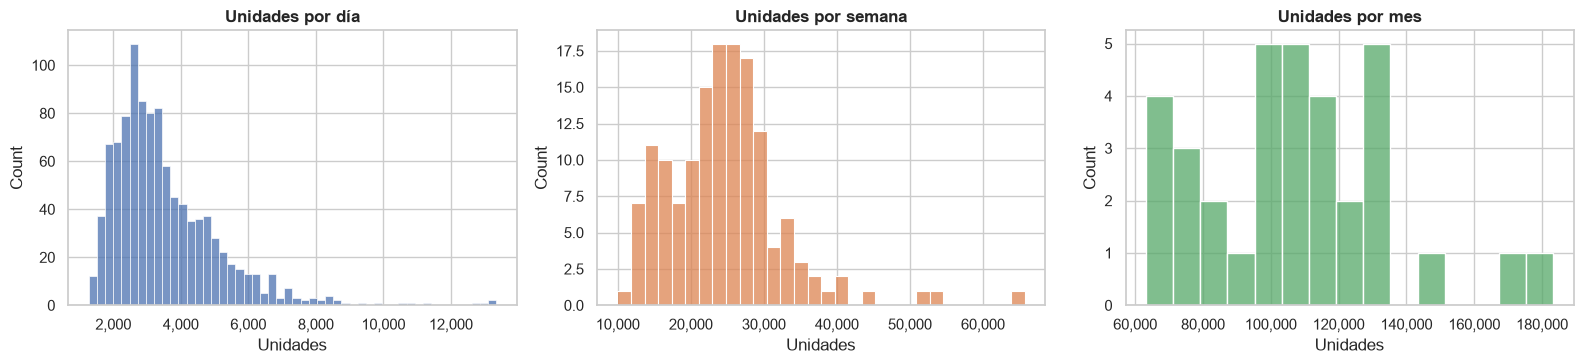

In [21]:
daily = df.groupby("date")["item_cnt_day"].sum()
weekly = daily.resample("W-MON").sum()
monthly = df.groupby(df["date"].dt.to_period("M"))["item_cnt_day"].sum()
df["year"] = df["date"].dt.year
yearly = df.groupby("year").agg(unidades=("item_cnt_day", "sum"), ingresos=("revenue", "sum"),
                                meses=("date_block_num", "nunique"))
yearly["unidades_por_mes"] = yearly["unidades"] / yearly["meses"]
jan_oct = df[df["date"].dt.month <= 10].groupby("year")["item_cnt_day"].sum().rename("unidades_ene_oct")
display(yearly.join(jan_oct))

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
sns.histplot(daily, bins=50, ax=axes[0]); axes[0].set(title="Unidades por día", xlabel="Unidades")
sns.histplot(weekly, bins=30, ax=axes[1], color="#DD8452"); axes[1].set(title="Unidades por semana", xlabel="Unidades")
sns.histplot(monthly, bins=15, ax=axes[2], color="#55A868"); axes[2].set(title="Unidades por mes", xlabel="Unidades")
for ax in axes:
    ax.xaxis.set_major_formatter(thousands)
plt.tight_layout()
plt.show()

- **Por año:** comparando enero–octubre, las unidades **caen año con año** (2013 > 2014 > 2015). Los **ingresos** no caen igual (2014 supera a 2013), señal de que el precio promedio sube: se venden menos unidades, pero más caras. Esto es consistente con la inflación en Rusia en 2014–2015 y con la migración a lo digital de cine y música.
- **Por día, semana y mes:** las distribuciones tienen cola a la derecha, por los picos de diciembre que se ven en la siguiente sección.

## 6. Exploración temporal

### 6.a Evolución de las ventas

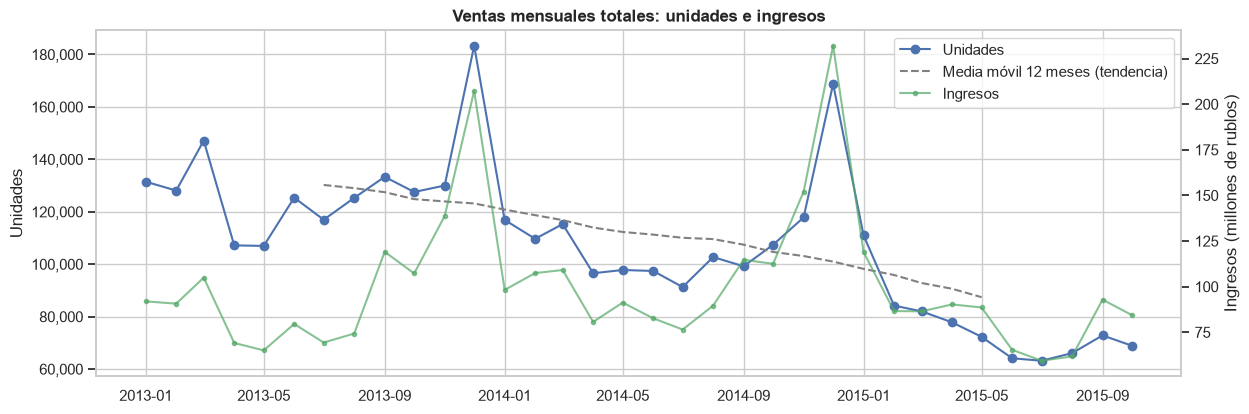

In [22]:
monthly_total = eda.monthly_series(df)
monthly_rev = eda.monthly_series(df, value="revenue")
month_index = pd.period_range("2013-01", periods=34, freq="M").to_timestamp()

fig, ax1 = plt.subplots(figsize=(14, 4.5))
ax1.plot(month_index, monthly_total.values, marker="o", label="Unidades")
ax1.plot(month_index, monthly_total.rolling(12, center=True).mean().values, "--", color="gray",
         label="Media móvil 12 meses (tendencia)")
ax1.set(title="Ventas mensuales totales: unidades e ingresos", ylabel="Unidades")
ax1.yaxis.set_major_formatter(thousands)
ax2 = ax1.twinx()
ax2.plot(month_index, monthly_rev.values / 1e6, color="#55A868", alpha=.7, marker=".", label="Ingresos")
ax2.set_ylabel("Ingresos (millones de rublos)")
ax2.grid(False)
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.88))
plt.show()

### 6.b Tendencia, estacionalidad, picos y ciclos

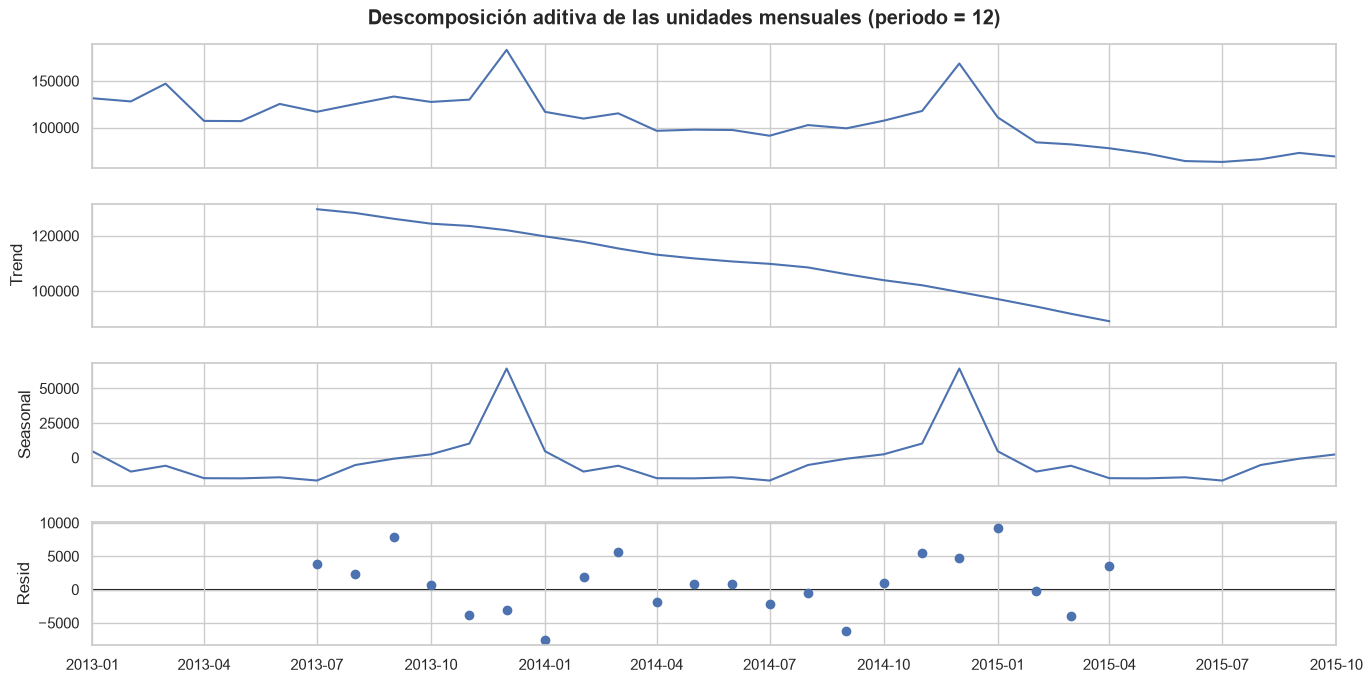

In [23]:
decomp = seasonal_decompose(pd.Series(monthly_total.values, index=month_index),
                            model="additive", period=12)
fig = decomp.plot()
fig.set_size_inches(14, 7)
fig.suptitle("Descomposición aditiva de las unidades mensuales (periodo = 12)", y=1.01, fontweight="bold")
plt.show()

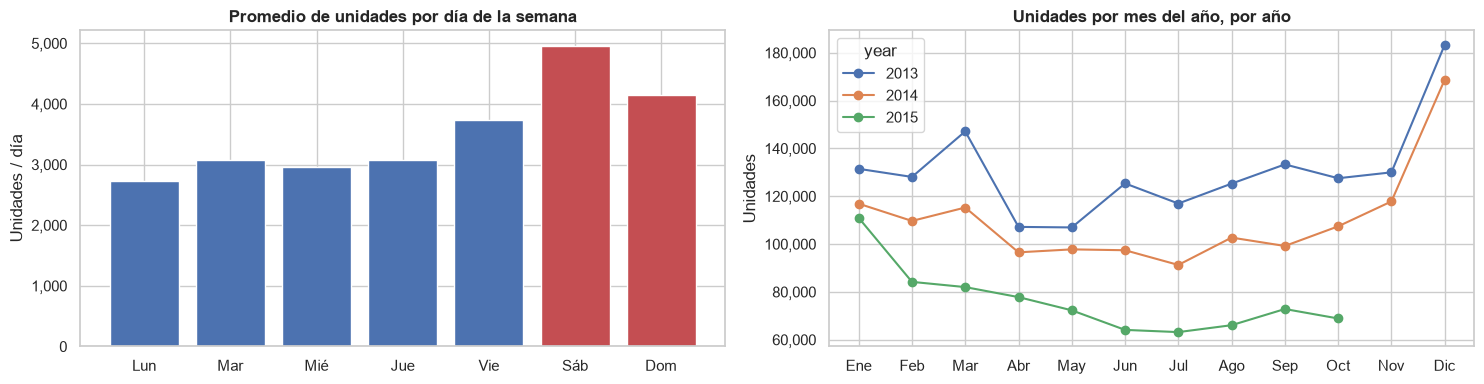

Días con más ventas:


,unidades
date,
2013-12-28,"13,343.00"
2014-12-30,"13,236.00"
2013-12-29,"12,863.00"
2013-12-30,"12,823.00"
2014-12-31,"11,393.00"
2014-12-27,"10,919.00"


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
dow = df.groupby(df["date"].dt.dayofweek)["item_cnt_day"].sum() / df.groupby(df["date"].dt.dayofweek)["date"].nunique()
axes[0].bar(eda.SPANISH_WEEKDAYS, dow.values, color=["#4C72B0"] * 5 + ["#C44E52"] * 2)
axes[0].set(title="Promedio de unidades por día de la semana", ylabel="Unidades / día")
axes[0].yaxis.set_major_formatter(thousands)

moy = df.groupby([df["year"], df["date"].dt.month])["item_cnt_day"].sum().unstack(0)
moy.index = eda.SPANISH_MONTHS
moy.plot(ax=axes[1], marker="o")
axes[1].set(title="Unidades por mes del año, por año", ylabel="Unidades", xlabel="")
axes[1].set_xticks(range(12)); axes[1].set_xticklabels(eda.SPANISH_MONTHS)
axes[1].yaxis.set_major_formatter(thousands)
plt.tight_layout()
plt.show()

print("Días con más ventas:")
display(daily.nlargest(6).to_frame("unidades"))

**Hallazgos temporales**

1. **Tendencia:** **decreciente** y clara. La media móvil y el componente de tendencia caen de forma sostenida desde 2013, con menos de la mitad de unidades mensuales en 2015 que en 2013. La serie **no es estacionaria en media**; lo confirma la prueba ADF de la sección 9.
2. **Estacionalidad anual:** **diciembre** es el pico de todos los años (compras navideñas y de Año Nuevo, la festividad más importante en Rusia). Después de diciembre hay una caída marcada en enero–febrero, y el valle está a mitad de año (mayo–julio). Hay un repunte menor en **marzo de 2013** y desde **septiembre–octubre** (temporada de lanzamientos de videojuegos y regreso a clases).
3. **Picos y caídas abruptas:** los días de mayor venta son el **27–31 de diciembre** de cada año. No se observan caídas abruptas por cierre de la cadena. La caída grande es la de enero, después del pico navideño.
4. **Ciclo semanal:** el **sábado** es el día más fuerte, seguido de domingo y viernes. De lunes a jueves las ventas son ~40–45 % menores que el sábado. Este ciclo se ve en la serie diaria; al agregar por mes se diluye, aunque el número de fines de semana de cada mes puede explicar parte de la variación mensual.
5. **Ingresos vs unidades:** los ingresos bajan menos que las unidades, porque el precio promedio sube con el tiempo.

## 7. Análisis comparativo entre sucursales y productos

### 7.a Productos y categorías más y menos vendidos

In [25]:
item_names = items.set_index("item_id")["item_name"]
top_items = by_item.nlargest(10).to_frame("unidades").join(item_names)
top_items["item_name"] = top_items["item_name"].str.slice(0, 60)
print("Top 10 productos por unidades:")
display(top_items)

cat_units = df.groupby(["item_category_id", "item_category_name", "category_group"])["item_cnt_day"].sum()
print("Top 10 categorías:")
display(cat_units.nlargest(10).to_frame("unidades"))
print("Categorías menos vendidas:")
display(cat_units.nsmallest(8).to_frame("unidades"))
print(f"Productos que se vendieron 1 sola unidad neta o menos en todo el periodo: {(by_item <= 1).sum():,}")

Top 10 productos por unidades:


,unidades,item_name
item_id,,
20949,"187,642.00",Фирменный пакет майка 1С Интерес белый (34*42)...
2808,"17,245.00","Diablo III [PC, Jewel, русская версия]"
3732,"16,642.00","Grand Theft Auto V [PS3, русские субтитры]"
17717,"15,830.00",Прием денежных средств для 1С-Онлайн
5822,"14,515.00",Playstation Store пополнение бумажника: Карта ...
3734,"11,688.00","Grand Theft Auto V [Xbox 360, русские субтитры]"
6675,"10,289.00",Sony PlayStation 4 (500 Gb) Black (CUH-1008A/1...
3731,"10,099.00","Grand Theft Auto V [PC, русские субтитры]"
1855,"10,032.00","Battlefield 4 [PC, русская версия]"


Top 10 categorías:


,,,unidades
item_category_id,item_category_name,category_group,
40,Кино - DVD,Cine,"634,170.00"
30,Игры PC - Стандартные издания,Juegos PC,"456,540.00"
55,Музыка - CD локального производства,Música,"348,591.00"
19,Игры - PS3,Juegos consola,"254,886.00"
37,Кино - Blu-Ray,Cine,"203,283.00"
71,"Подарки - Сумки, Альбомы, Коврики д/мыши",Regalos,"187,998.00"
28,Игры PC - Дополнительные издания,Juegos PC,"174,954.00"
23,Игры - XBOX 360,Juegos consola,"169,940.00"
20,Игры - PS4,Juegos consola,"127,319.00"


Categorías menos vendidas:


,,,unidades
item_category_id,item_category_name,category_group,
10,Игровые консоли - PS2,Consolas,1.00
51,Книги - Познавательная литература,Libros,1.00
1,Аксессуары - PS2,Accesorios,2.00
0,PC - Гарнитуры/Наушники,PC,3.00
50,Книги - Открытки,Libros,3.00
52,Книги - Путеводители,Libros,3.00
53,Книги - Художественная литература,Libros,3.00
48,Книги - Компьютерная литература,Libros,6.00


Productos que se vendieron 1 sola unidad neta o menos en todo el periodo: 2,326


- El producto #1 por mucho (`20949`) es la **bolsa de compra de marca** ("Фирменный пакет майка 1С Интерес"), un artículo que acompaña otras compras y no un producto en sí. Distorsiona los rankings y conviene tratarlo como caso especial en el modelo.
- Después vienen **videojuegos de gran lanzamiento** (Diablo III, GTA V en varias plataformas, Battlefield 4, The Last of Us), una **consola PS4**, y servicios como **pagos 1C-Online** y **tarjetas de PlayStation Store**.
- Por categoría dominan **Cine – DVD**, **Juegos PC – Estándar**, **Música – CD local**, **Juegos – PS3** y **Cine – Blu-Ray**.
- Las **menos vendidas** son libros especializados, accesorios y consolas PS2 (tecnología obsoleta), con apenas algunas unidades en 3 años.
- Miles de productos vendieron una unidad o menos: la **dispersión** es el reto central del forecasting.

### 7.b Desempeño entre sucursales

In [26]:
shop_month = eda.monthly_series(df, by=["shop_id"])
active = (shop_month > 0)
shop_perf = pd.DataFrame({
    "unidades_por_mes_activo": shop_month.sum() / active.sum(),
    "meses_activos": active.sum(),
    "ultimo_mes": active[::-1].idxmax(),
    "en_test": shop_month.columns.isin(test["shop_id"].unique()),
}).sort_values("unidades_por_mes_activo", ascending=False)
shop_perf["cambio_%_2015_vs_2013"] = (
    (shop_month.loc[24:33].mean() / shop_month.loc[0:9].replace(0, np.nan).mean() - 1) * 100)
shop_perf.head(12)

,unidades_por_mes_activo,meses_activos,ultimo_mes,en_test,cambio_%_2015_vs_2013
shop_id,,,,,
31,"9,140.50",34,33,True,-35.23
25,"7,115.26",34,33,True,-30.82
54,"6,635.32",28,27,False,-80.05
28,"5,428.15",34,33,True,-37.21
9,"5,288.67",3,33,False,-95.12
57,"4,494.47",34,33,True,-50.62
27,"4,408.29",31,30,False,-36.91
42,"4,262.74",34,33,True,-2.74
6,"2,955.56",34,33,True,-50.24


In [27]:
print("Tiendas que dejaron de vender antes de oct-2015 (cerradas):")
display(shop_perf[shop_perf["ultimo_mes"] < 33])
print("Tiendas que abrieron después de ene-2013:")
display(shop_perf[active.idxmax() > 0].join(active.idxmax().rename("primer_mes")))

Tiendas que dejaron de vender antes de oct-2015 (cerradas):


,unidades_por_mes_activo,meses_activos,ultimo_mes,en_test,cambio_%_2015_vs_2013
shop_id,,,,,
54,"6,635.32",28,27,False,-80.05
27,"4,408.29",31,30,False,-36.91
30,"2,339.54",26,25,False,-90.54
29,"2,024.59",29,28,False,-75.76
43,"2,024.32",25,24,False,-93.43
23,"1,926.25",4,3,False,-100.00
51,"1,477.79",33,32,False,-71.20
17,"1,291.90",20,24,False,-94.36
32,"1,254.29",7,6,False,-100.00


Tiendas que abrieron después de ene-2013:


,unidades_por_mes_activo,meses_activos,ultimo_mes,en_test,cambio_%_2015_vs_2013,primer_mes
shop_id,,,,,,
9,"5,288.67",3,33,False,-95.12,9
20,"2,936.00",2,33,False,NaN,21
55,"2,112.93",30,33,True,294.07,4
48,"1,311.00",19,33,True,NaN,15
5,"1,295.82",33,33,True,-10.16,1
17,"1,291.90",20,24,False,-94.36,5
39,830.85,20,33,True,NaN,14
49,743.04,23,33,True,NaN,11
33,685.25,8,26,False,NaN,19


- La **tienda 31** (Москва ТЦ "Семеновский") es la líder, seguida por la **25** (Москва ТРК "Атриум"), la **54** (Химки "Мега"), la **28** y la **42** (San Petersburgo): las tiendas de Moscú y San Petersburgo dominan.
- La mayoría de las tiendas **cae entre 2013 y 2015**, en línea con la tendencia general, pero el ritmo de caída varía entre tiendas. Eso justifica usar variables a nivel tienda en el modelo.
- **Varias tiendas cerraron** antes de octubre 2015 (por ejemplo, 54, 30, 29 y 43). Ninguna de ellas está en `test`, que solo incluye tiendas activas al final del periodo. **La tienda 36** abrió en el último mes, así que casi no tiene historial pero sí está en `test`.
- **Tiendas especiales:**
  - `9` "Выездная Торговля" (ventas itinerantes, solo algunos meses del año, en ferias).
  - `12` "Интернет-магазин ЧС" (tienda online).
  - `55` "Цифровой склад 1С-Онлайн" (almacén digital, solo vende productos digitales).
  - `20` "Москва Распродажа" (liquidaciones).

### 7.c Outliers y comportamientos anómalos

In [28]:
q99 = df["item_cnt_day"].quantile(0.999)
bulk = df[df["item_cnt_day"] > q99]
print(f"Percentil 99.9 de item_cnt_day: {q99:.0f} unidades")
print(f"Transacciones por encima del p99.9: {len(bulk):,}")
display(bulk.groupby("shop_id").size().nlargest(6).to_frame("transacciones_masivas"))

# precio de un mismo producto: variación anómala
price_cv = df.groupby("item_id")["item_price"].agg(["mean", "std", "count"])
price_cv["cv"] = price_cv["std"] / price_cv["mean"]
print("Productos con mayor variación de precio (con >= 50 transacciones):")
display(price_cv[price_cv["count"] >= 50].nlargest(5, "cv").join(item_names.str.slice(0, 50)))

Percentil 99.9 de item_cnt_day: 22 unidades
Transacciones por encima del p99.9: 2,881


,transacciones_masivas
shop_id,
31,502
25,316
12,288
54,232
28,200
55,168


Productos con mayor variación de precio (con >= 50 transacciones):


,mean,std,count,cv,item_name
item_id,,,,,
11860,16.05,64.89,77,4.04,Змей ВАСЯ с цветком 40 см
11872,18.01,60.88,150,3.38,Змея ВАСИЛИСА 23 см
11866,27.24,83.58,137,3.07,Змей ФАНТИК 23 см
11855,26.58,67.26,101,2.53,Змей ВАСЯ 33 см
11856,37.92,89.12,107,2.35,Змей ВАСЯ 40 см


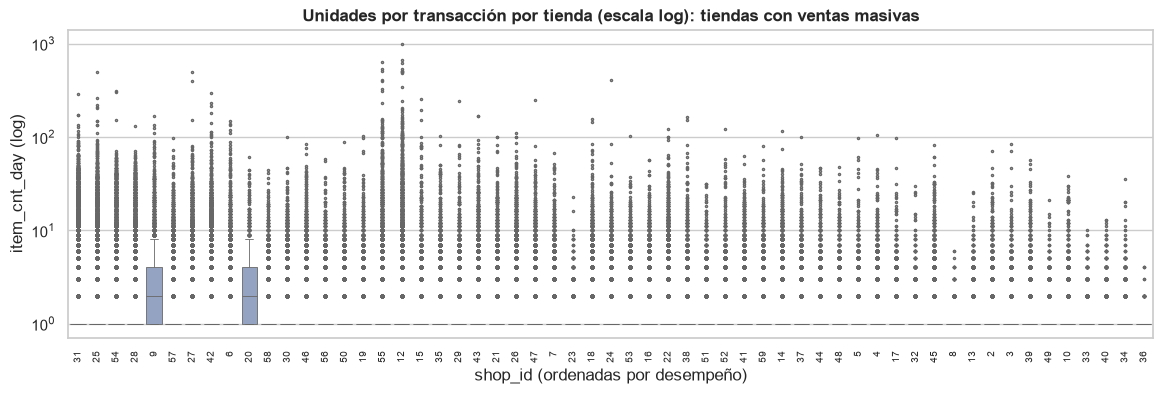

In [29]:
fig, ax = plt.subplots(figsize=(14, 4))
order = shop_perf.index
sns.boxplot(data=df[df["item_cnt_day"] > 0], x="shop_id", y="item_cnt_day", order=order,
            ax=ax, fliersize=1.5, linewidth=.6, color="#8DA0CB")
ax.set_yscale("log")
ax.set(title="Unidades por transacción por tienda (escala log): tiendas con ventas masivas",
       xlabel="shop_id (ordenadas por desempeño)", ylabel="item_cnt_day (log)")
ax.tick_params(axis="x", labelsize=7, rotation=90)
plt.show()

- Las transacciones por encima del p99.9 (más de 22 unidades en un día) aparecen sobre todo en las tiendas más grandes (`31`, `25`), en la **tienda online `12`** y en el **almacén digital `55`**. Los casos de **cientos de unidades** se concentran en la tienda `12` (4 de las 5 transacciones más grandes). Son patrones de negocio distintos (ventas al mayoreo o de códigos digitales), no errores. Por eso no se eliminaron, salvo el caso extremo de 2,169 unidades a precio casi cero.
- Hay productos cuyo precio **varía mucho** entre transacciones. Los de mayor variación son **peluches** (serpientes *Змей ВАСЯ*, *ФАНТИК*), que casi siempre se registran a un precio simbólico (regalo o promoción) y a veces a precio normal. Para el modelo conviene usar el precio **promedio mensual** por producto, no el precio de cada transacción.
- Las tiendas con pocos meses activos (9, 20, 36 y las cerradas) son series cortas o intermitentes y requieren un tratamiento especial (por ejemplo, usar promedios de la categoría).

## 8. Visualizaciones clave

### 8.a Serie de tiempo de ventas totales

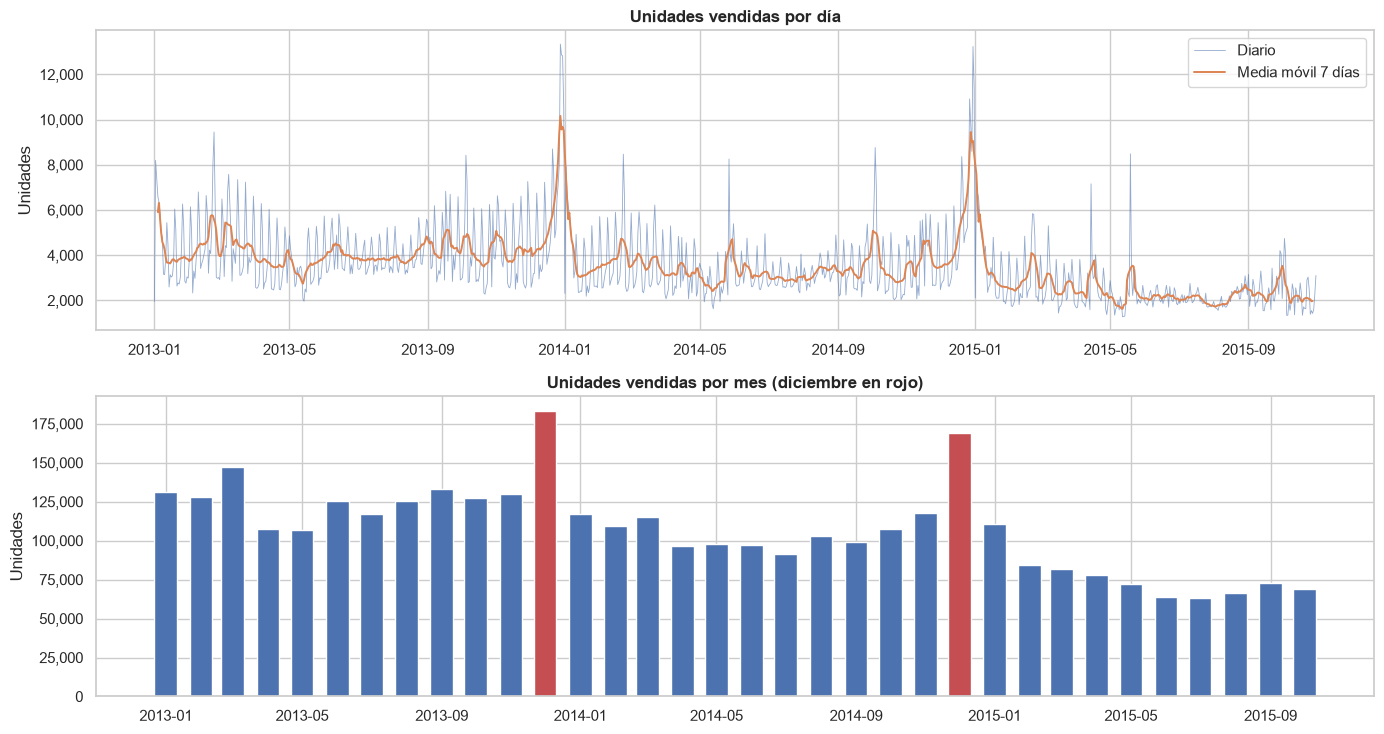

In [30]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7.5), sharex=False)
axes[0].plot(daily.index, daily.values, lw=.6, alpha=.6, label="Diario")
axes[0].plot(daily.index, daily.rolling(7, center=True).mean(), lw=1.4, label="Media móvil 7 días")
axes[0].set(title="Unidades vendidas por día", ylabel="Unidades")
axes[0].legend()
axes[1].bar(month_index, monthly_total.values, width=20,
            color=["#C44E52" if m.month == 12 else "#4C72B0" for m in month_index])
axes[1].set(title="Unidades vendidas por mes (diciembre en rojo)", ylabel="Unidades")
for ax in axes:
    ax.yaxis.set_major_formatter(thousands)
plt.tight_layout()
eda.save_fig(fig, "01_serie_ventas_totales")
plt.show()

La serie diaria muestra el ciclo semanal (oscilación de alta frecuencia) y los picos de fin de año. La mensual deja ver la **tendencia a la baja** y el **pico de diciembre**: ese es el patrón que el modelo debe capturar. **Noviembre**, el mes a predecir, fue ligeramente **mayor que octubre** en ambos años (+2 % en 2013 y +10 % en 2014): es la antesala del pico de diciembre.

### 8.b Ventas por sucursal

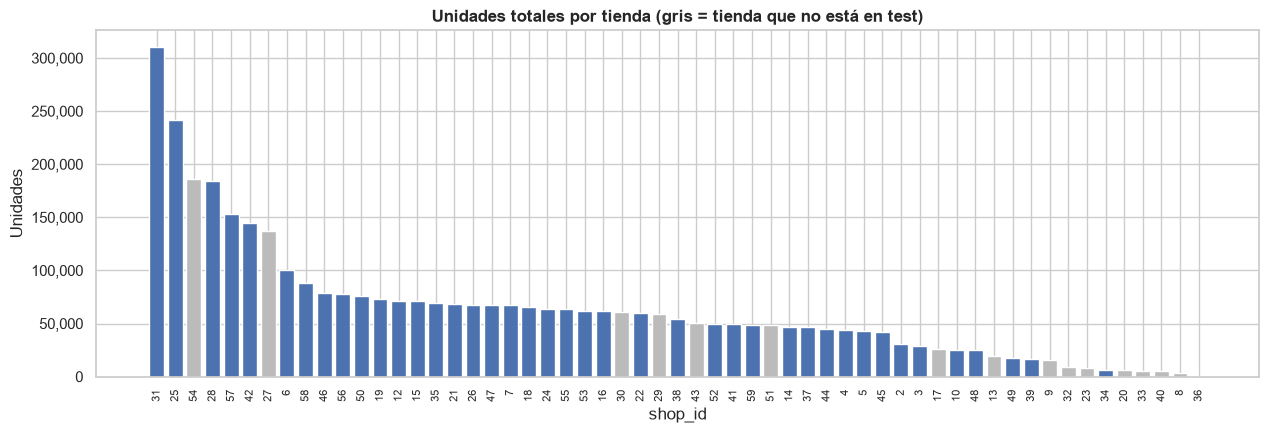

In [31]:
shop_units = df.groupby("shop_id")["item_cnt_day"].sum().sort_values(ascending=False)
colors = ["#4C72B0" if s in set(test["shop_id"]) else "#BBBBBB" for s in shop_units.index]
fig, ax = plt.subplots(figsize=(15, 4.5))
ax.bar(shop_units.index.astype(str), shop_units.values, color=colors)
ax.set(title="Unidades totales por tienda (gris = tienda que no está en test)",
       xlabel="shop_id", ylabel="Unidades")
ax.yaxis.set_major_formatter(thousands)
ax.tick_params(axis="x", labelsize=8, rotation=90)
eda.save_fig(fig, "02_ventas_por_tienda")
plt.show()

Hay una **gran desigualdad** entre tiendas: la `31` vende ~30 % más que la segunda (`25`) y más de 10 veces lo que venden las tiendas pequeñas. Las tiendas en gris (cerradas o especiales) no se predicen, pero sí aportan información histórica de los productos.

### 8.c Ventas por producto (top N) y por categoría

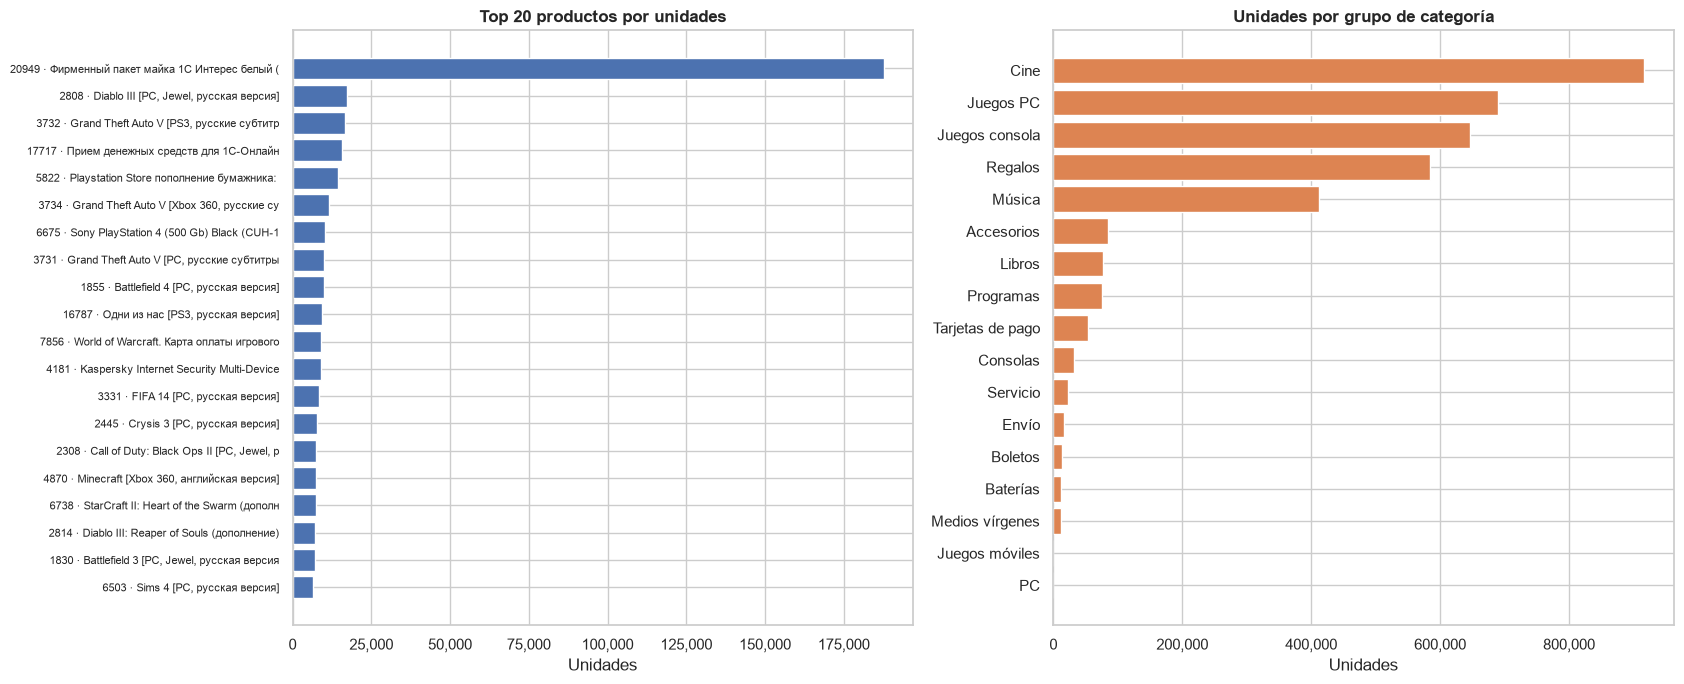

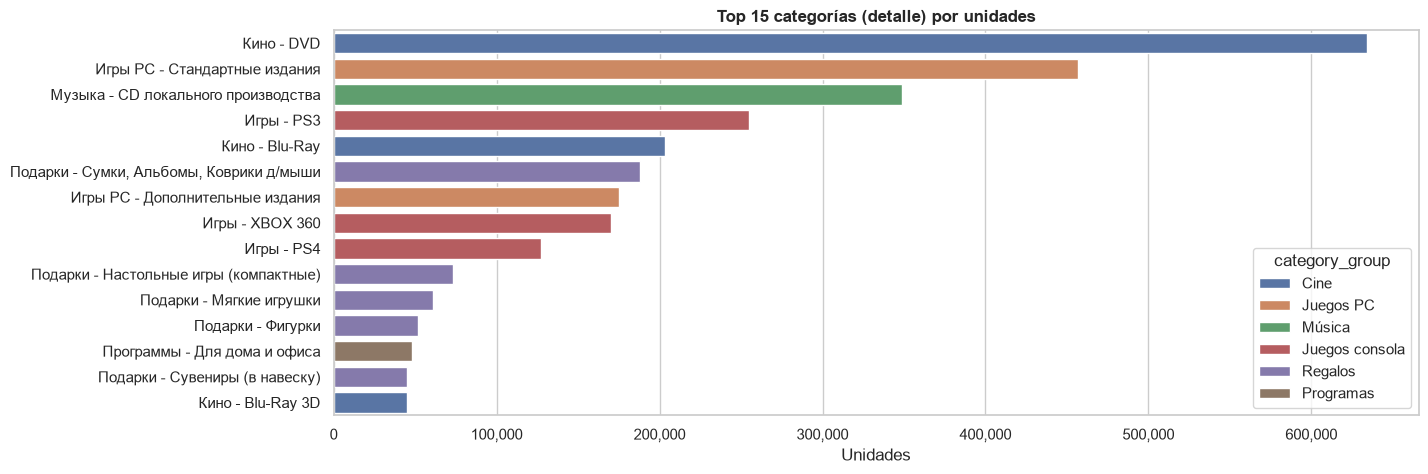

In [32]:
N = 20
top_n = by_item.nlargest(N).to_frame("unidades").join(item_names)
top_n["etiqueta"] = top_n.index.astype(str) + " · " + top_n["item_name"].str.slice(0, 40)

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
axes[0].barh(top_n["etiqueta"][::-1], top_n["unidades"][::-1], color="#4C72B0")
axes[0].set(title=f"Top {N} productos por unidades", xlabel="Unidades")
axes[0].xaxis.set_major_formatter(thousands)
axes[0].tick_params(axis="y", labelsize=8)

grp = by_group.sort_values("unidades")
axes[1].barh(grp.index, grp["unidades"], color="#DD8452", label="Unidades")
axes[1].set(title="Unidades por grupo de categoría", xlabel="Unidades")
axes[1].xaxis.set_major_formatter(thousands)
plt.tight_layout()
eda.save_fig(fig, "03_ventas_por_producto_categoria")
plt.show()

top_cats = cat_units.nlargest(15).reset_index()
fig, ax = plt.subplots(figsize=(14, 5))
sns.barplot(data=top_cats, y="item_category_name", x="item_cnt_day", hue="category_group",
            dodge=False, ax=ax)
ax.set(title="Top 15 categorías (detalle) por unidades", xlabel="Unidades", ylabel="")
ax.xaxis.set_major_formatter(thousands)
plt.show()

- Fuera de la bolsa de compra (`20949`), el top 20 está dominado por **videojuegos AAA** y por **servicios y tarjetas de pago**, cuyas ventas se concentran en las semanas posteriores a su lanzamiento. La **antigüedad del producto desde su primera venta** será una variable importante.
- Por grupo, **Cine** y **Juegos** (sumando consola y PC) explican la mayor parte del volumen.

### 8.d Heatmap tiempo × sucursal / categoría

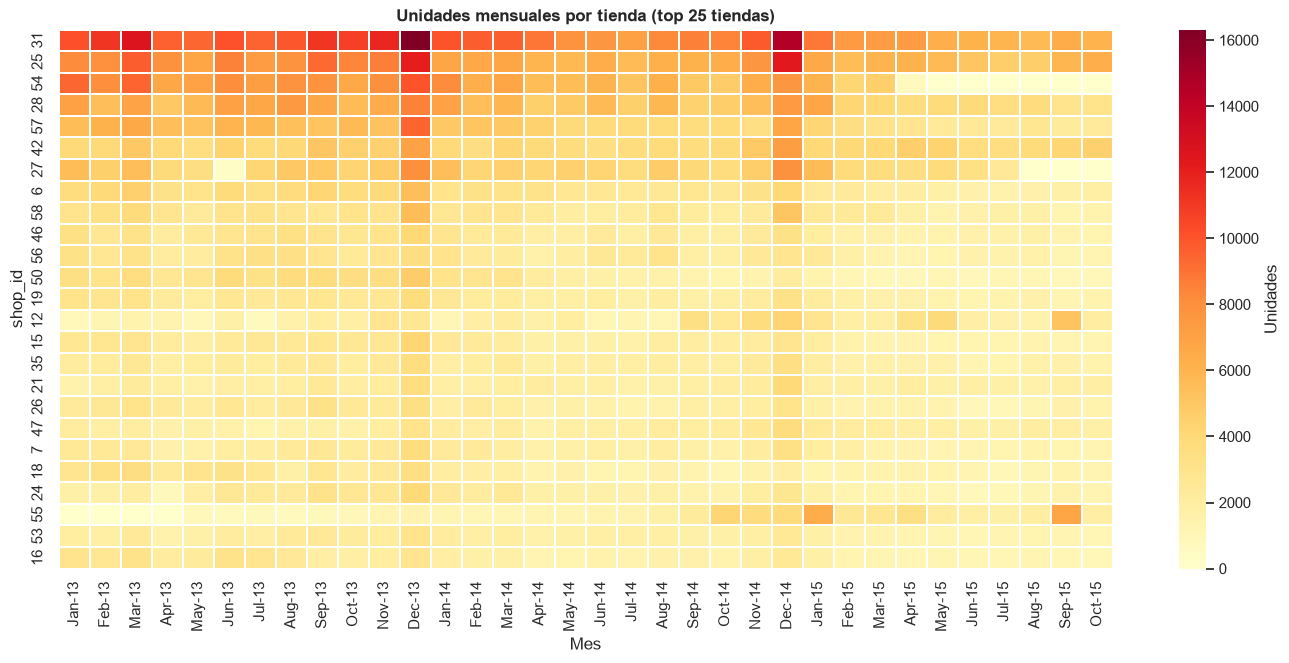

In [33]:
month_labels = [d.strftime("%b-%y") for d in month_index]

top_shops = shop_units.index[:25]
heat_shop = shop_month[top_shops].T
heat_shop.columns = month_labels
fig, ax = plt.subplots(figsize=(17, 7))
sns.heatmap(heat_shop, cmap="YlOrRd", ax=ax, cbar_kws={"label": "Unidades"}, linewidths=.2)
ax.set(title="Unidades mensuales por tienda (top 25 tiendas)", xlabel="Mes", ylabel="shop_id")
eda.save_fig(fig, "04_heatmap_tienda_mes")
plt.show()

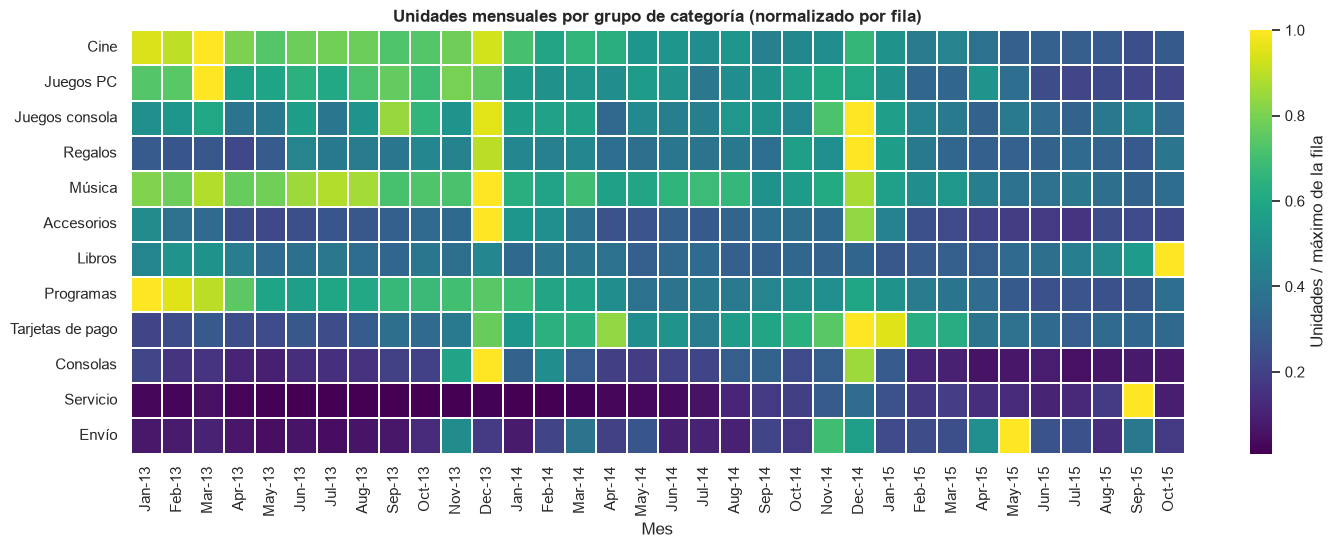

In [34]:
group_month = eda.monthly_series(df, by=["category_group"])
heat_grp = group_month[by_group.index[:12]].T
heat_grp = heat_grp.div(heat_grp.max(axis=1), axis=0)   # normalizado por fila para ver la forma
heat_grp.columns = month_labels
fig, ax = plt.subplots(figsize=(17, 5.5))
sns.heatmap(heat_grp, cmap="viridis", ax=ax, cbar_kws={"label": "Unidades / máximo de la fila"},
            linewidths=.2)
ax.set(title="Unidades mensuales por grupo de categoría (normalizado por fila)", xlabel="Mes", ylabel="")
eda.save_fig(fig, "05_heatmap_categoria_mes")
plt.show()

- **Tiendas × mes:** las columnas de **diciembre** (dic-13 y dic-14) se iluminan en casi todas las tiendas, así que la estacionalidad es **común a la cadena**. También se ven filas que **se apagan** (tiendas que cierran, como la 54 desde may-15) y filas que **se encienden tarde** (aperturas). Las tiendas grandes se van "enfriando" con el tiempo.
- **Categorías × mes (normalizado):**
  - **Cine, Música y Juegos PC** tienen su máximo en 2013 y caen después: son formatos físicos en declive.
  - **Juegos de consola** tienen picos en los lanzamientos de fin de año, y **Consolas** se enciende en **nov–dic 2013** con el lanzamiento de PS4 y Xbox One.
  - **Tarjetas de pago** y **Regalos** crecen o se mantienen hacia 2015.

  El mix de productos **cambia con el tiempo**: no basta con modelar el total, la categoría importa.

## 9. Autocorrelación (ACF) y autocorrelación parcial (PACF)

Con 60 tiendas y más de 21,000 productos, se trabaja con una **selección representativa**: las series con más ventas que además tienen historial completo. Las series se agregan a nivel **mensual** (34 observaciones, rezagos hasta 16) y, para el total, también a nivel **diario** (rezagos hasta 35, para ver el ciclo semanal).

Con 34 observaciones, la banda de significancia al 95 % es aproximadamente ±2/√34 ≈ **±0.34**: solo las barras que salen de la zona sombreada son significativas.

### 9.1 Ventas totales (mensual y diaria)

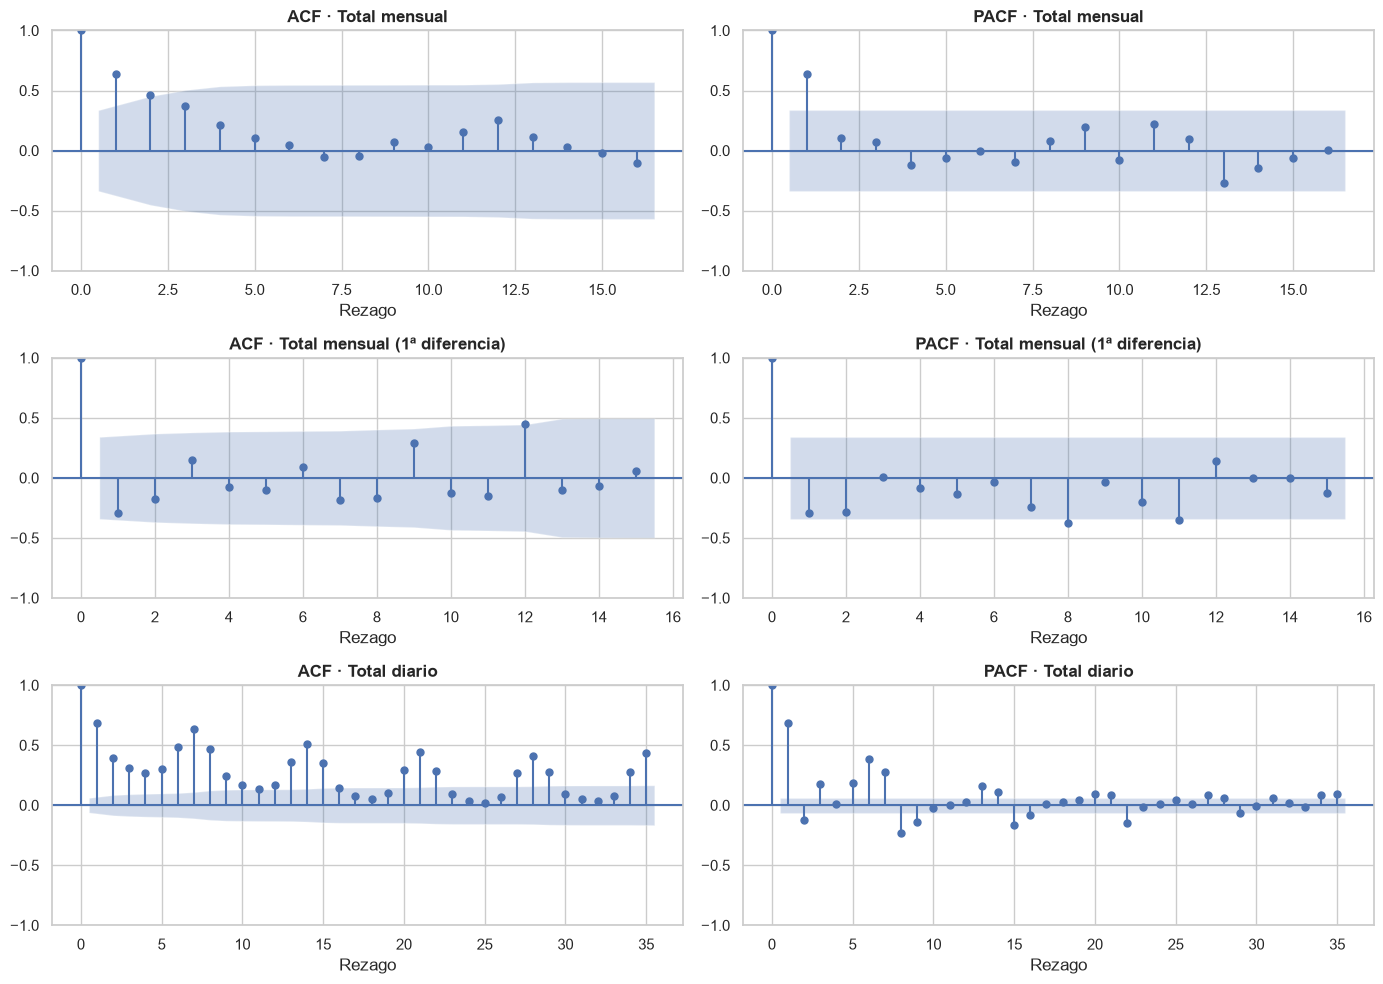

ADF Mensual         : estadístico =  -2.37 · p-valor = 0.151 -> NO estacionaria
ADF Mensual 1ª dif. : estadístico = -13.17 · p-valor = 0.000 -> estacionaria
ADF Diaria          : estadístico =  -4.01 · p-valor = 0.001 -> estacionaria


In [35]:
fig, axes = plt.subplots(3, 2, figsize=(14, 10))
eda.plot_acf_pacf(monthly_total, lags=16, title="Total mensual", axes=axes[0])
eda.plot_acf_pacf(monthly_total.diff().dropna(), lags=16, title="Total mensual (1ª diferencia)",
                  axes=axes[1])
eda.plot_acf_pacf(daily, lags=35, title="Total diario", axes=axes[2])
plt.tight_layout()
plt.show()

for name, serie in [("Mensual", monthly_total), ("Mensual 1ª dif.", monthly_total.diff().dropna()),
                    ("Diaria", daily)]:
    stat, p, *_ = adfuller(serie, autolag="AIC")
    print(f"ADF {name:16s}: estadístico = {stat:6.2f} · p-valor = {p:.3f} -> "
          f"{'estacionaria' if p < 0.05 else 'NO estacionaria'}")

- **Mensual en niveles:**
  - La ACF decae **lentamente** desde el rezago 1 (≈ 0.64), típico de una serie con **tendencia**; la prueba ADF confirma que **no es estacionaria**.
  - La PACF tiene un único pico claro en el **rezago 1**, lo que sugiere un componente **AR(1)**.
  - En el **rezago 12** la ACF vuelve a subir (≈ 0.26). Es el eco del pico de diciembre: la estacionalidad anual está presente, aunque con solo 2.8 años de datos no alcanza la banda de significancia.
- **Primera diferencia:** quita la tendencia (ADF ahora significativo) y el **rezago 12 de la ACF (≈ 0.45) sale de la banda**: la estacionalidad anual queda confirmada una vez que se elimina la tendencia. Sugiere usar una diferencia regular y una componente estacional de periodo 12 (estilo SARIMA) o, en modelos de ML, variables de **lag 1** y **lag 12**.
- **Diaria:** picos claros en los rezagos **7, 14, 21, 28 y 35**, la firma del **ciclo semanal**. Confirma la estacionalidad semanal a nivel diario, que desaparece al agregar por mes.

### 9.2 Ventas por sucursal

Tiendas seleccionadas (más ventas, historial completo, en test): [31, 25, 28]


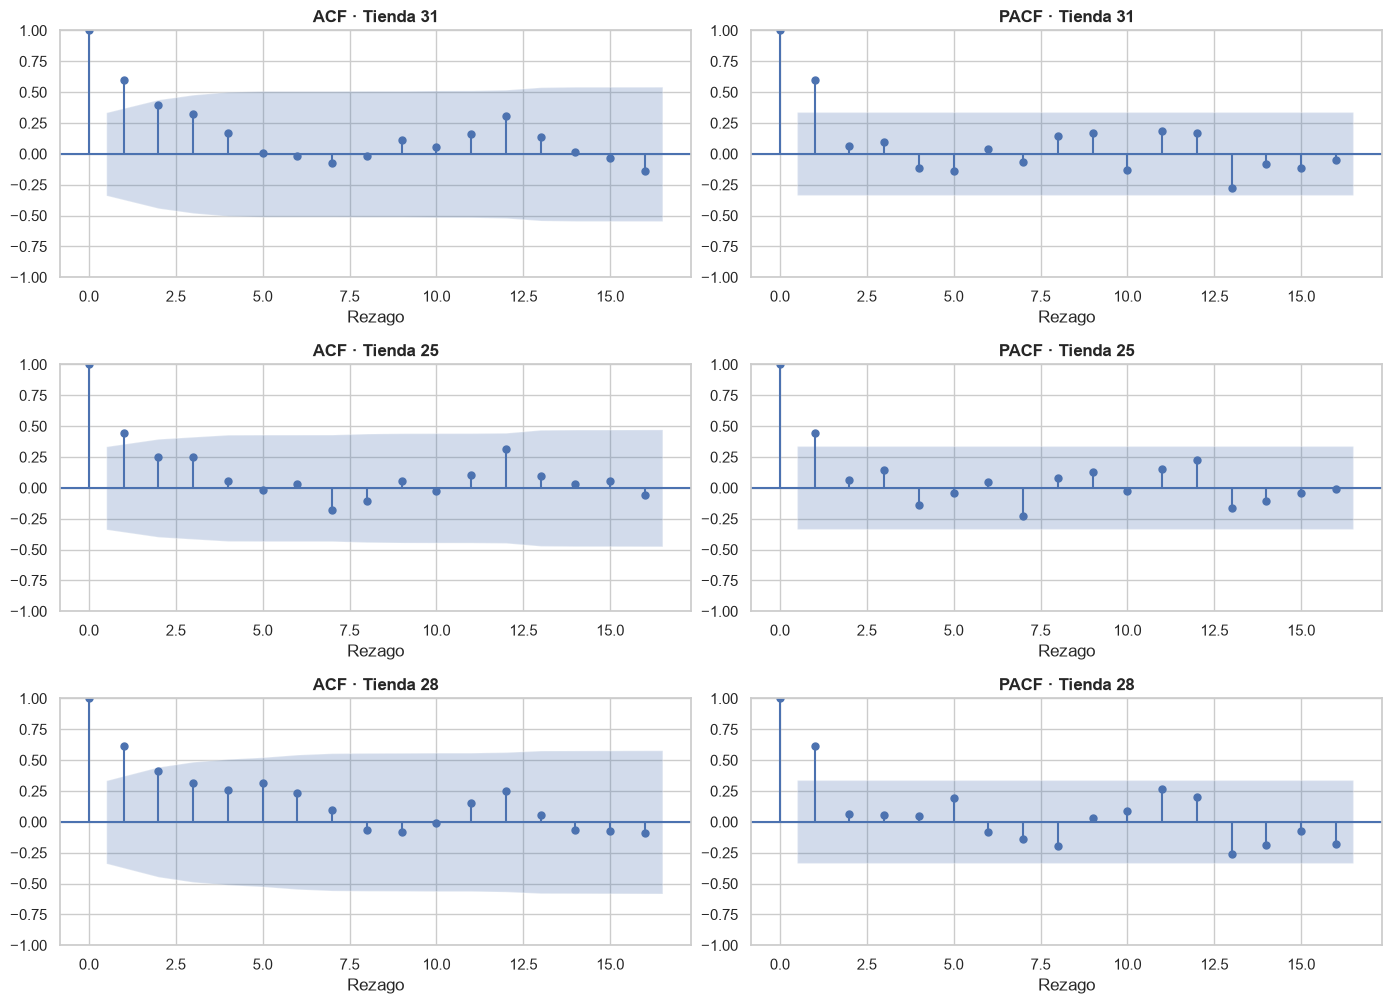

In [36]:
test_shops = set(test["shop_id"])
full_shops = shop_month.columns[(shop_month > 0).all()]
sel_shops = [s for s in shop_units.index if s in full_shops and s in test_shops][:3]
print("Tiendas seleccionadas (más ventas, historial completo, en test):", sel_shops)

fig, axes = plt.subplots(len(sel_shops), 2, figsize=(14, 3.4 * len(sel_shops)))
for row, s in zip(axes, sel_shops):
    eda.plot_acf_pacf(shop_month[s], lags=16, title=f"Tienda {s}", axes=row)
plt.tight_layout()
plt.show()

Las tiendas grandes **replican el patrón del total**: la ACF tiene un decaimiento lento (tendencia descendente), la PACF muestra un pico en el rezago 1 y la ACF sube en el rezago 12 (diciembre). La dinámica es bastante homogénea entre tiendas, así que **un modelo global** (todas las tiendas juntas, con `shop_id` como variable) es razonable.

### 9.3 Ventas por producto

Productos seleccionados (más ventas con >= 30 meses de historia):


,item_name
item_id,
20949,Фирменный пакет майка 1С Интерес белый (34*42)...
2808,"Diablo III [PC, Jewel, русская версия]"
17717,Прием денежных средств для 1С-Онлайн


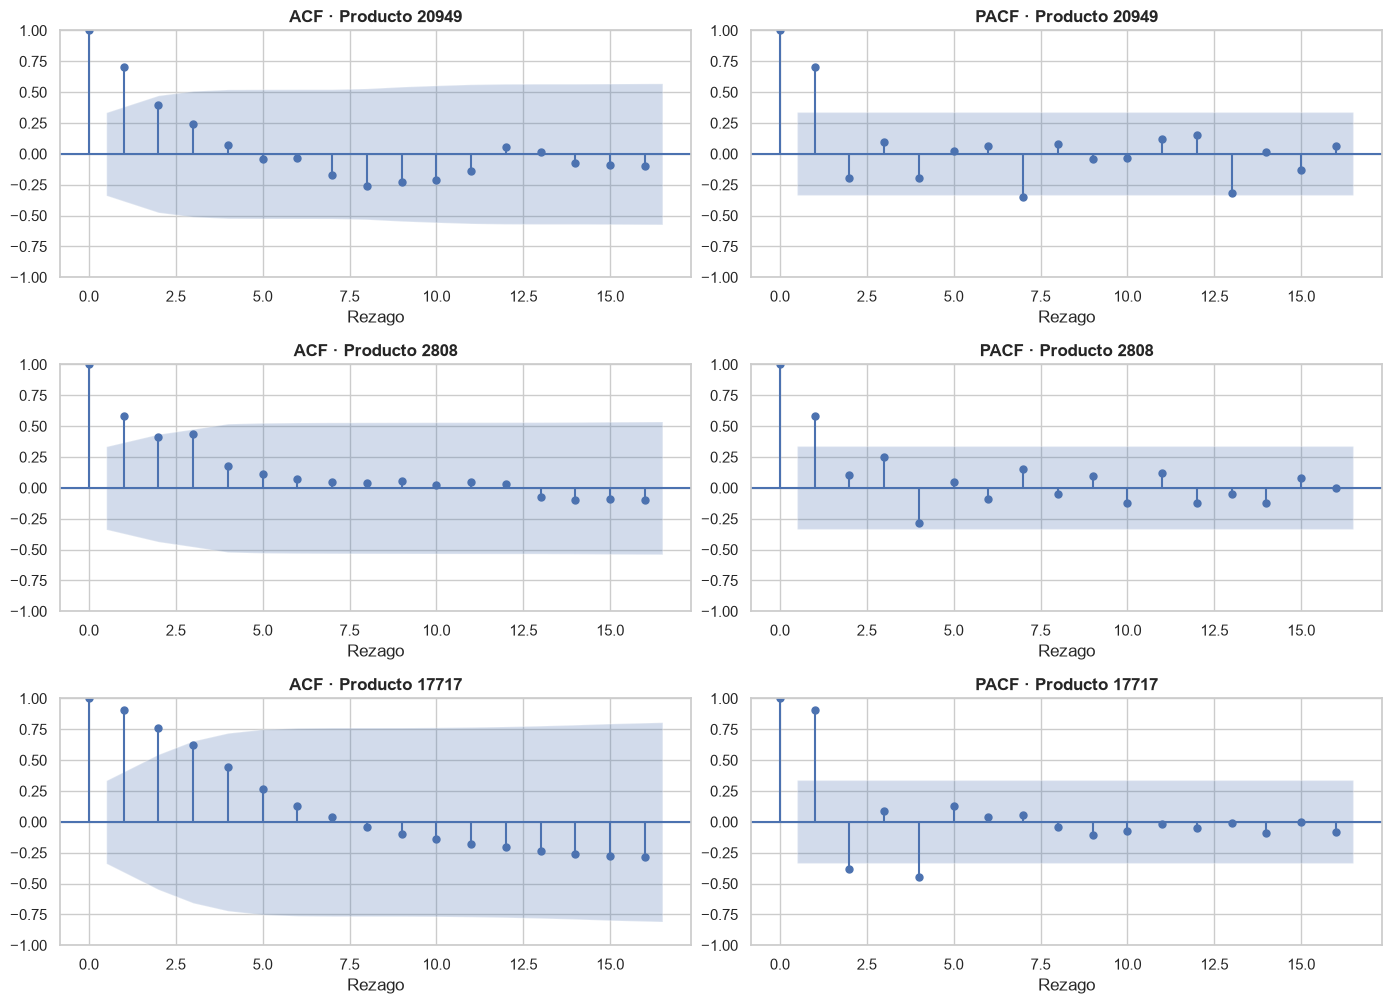

In [37]:
item_month = eda.monthly_series(df, by=["item_id"])
long_items = item_month.columns[(item_month > 0).sum() >= 30]
sel_items = by_item[by_item.index.isin(long_items)].nlargest(3).index.tolist()
print("Productos seleccionados (más ventas con >= 30 meses de historia):")
display(item_names.loc[sel_items].str.slice(0, 60).to_frame())

fig, axes = plt.subplots(len(sel_items), 2, figsize=(14, 3.4 * len(sel_items)))
for row, i in zip(axes, sel_items):
    eda.plot_acf_pacf(item_month[i], lags=16, title=f"Producto {i}", axes=row)
plt.tight_layout()
plt.show()

A nivel producto la dinámica es **más heterogénea**:
- La **bolsa de compra (`20949`)** y **Diablo III (`2808`)** tienen una autocorrelación fuerte solo en los primeros rezagos (1–3), que se desvanece rápido; no muestran un eco claro en el rezago 12.
- **`17717` (recepción de pagos 1C-Online)** tiene una ACF que decae muy lentamente: es una serie con **tendencia propia**, distinta de la del total.

En casi todos el **rezago 1** es significativo en la PACF: **las ventas del mes pasado son el mejor predictor individual** del mes siguiente.

### 9.4 Ventas por sucursal-producto

Pares seleccionados (top de cada tienda, >= 24 meses con venta): [(np.int64(31), np.int64(5822)), (np.int64(25), np.int64(2808)), (np.int64(28), np.int64(5822))]


,item_name
item_id,
5822,Playstation Store пополнение бумажника: Карта ...
2808,"Diablo III [PC, Jewel, русская версия]"
5822,Playstation Store пополнение бумажника: Карта ...


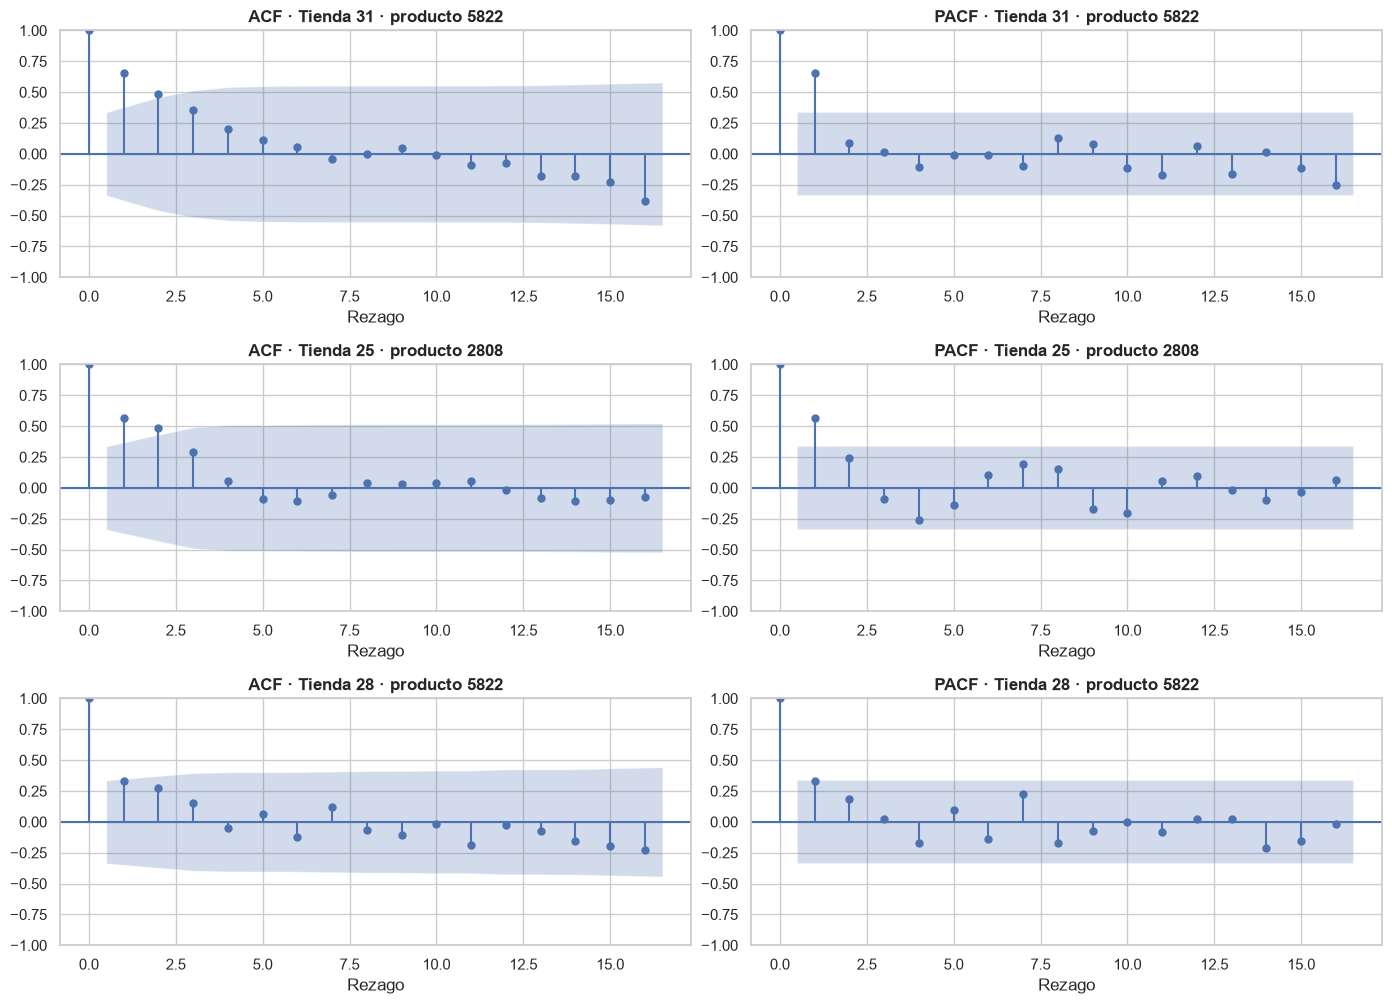

Mediana del % de meses SIN venta por par tienda-producto: 94%


In [38]:
pair_month = eda.monthly_series(df[df["item_id"].isin(long_items)], by=["shop_id", "item_id"])
pair_month = pair_month.loc[:, (pair_month > 0).sum() >= 24]
# el par más vendido de cada tienda analizada en 9.2, sin la bolsa de compra (20949)
pair_month = pair_month.loc[:, pair_month.columns.get_level_values("item_id") != 20949]
pair_totals = pair_month.sum()
sel_pairs = [pair_totals.xs(s, level="shop_id", drop_level=False).idxmax() for s in sel_shops]
print("Pares seleccionados (top de cada tienda, >= 24 meses con venta):", sel_pairs)
display(item_names.loc[[p[1] for p in sel_pairs]].str.slice(0, 60).to_frame())

fig, axes = plt.subplots(len(sel_pairs), 2, figsize=(14, 3.4 * len(sel_pairs)))
for row, p in zip(axes, sel_pairs):
    eda.plot_acf_pacf(pair_month[p], lags=16, title=f"Tienda {p[0]} · producto {p[1]}", axes=row)
plt.tight_layout()
plt.show()

zero_share = (eda.monthly_series(df, by=["shop_id", "item_id"]) == 0).mean().median()
print(f"Mediana del % de meses SIN venta por par tienda-producto: {zero_share:.0%}")

- Se analizaron los pares más vendidos de las tiendas 31, 25 y 28: tarjetas de PlayStation Store (`5822`) y Diablo III (`2808`).
- En los pares `31·5822` y `25·2808` solo el **rezago 1** es significativo en la PACF (≈ 0.6), y la ACF decae en 2–3 meses. En el par `28·5822` **ningún rezago sale de la banda**: la serie ya se comporta casi como ruido.
- No aparece eco en el rezago 12. A este nivel la estacionalidad anual queda enterrada en el ruido, así que conviene aportarla con variables agregadas (tienda, categoría o mes del año).
- El par típico tiene **la gran mayoría de sus meses en cero**: es una serie **intermitente**, para la que ARIMA por par no es viable.

### 9.5 Interpretación

**¿Existen correlaciones significativas a distintos rezagos?** Sí.
- El **rezago 1** es significativo en todos los niveles de agregación (total, tienda, producto y la mayoría de los pares): hay fuerte persistencia mes a mes. La PACF corta después del rezago 1, lo que apunta a un término **AR(1)**.
- En la serie diaria son significativos los **múltiplos de 7**.

**¿Se observa estacionalidad en patrones repetitivos?** Sí.
- **Anual:** la ACF vuelve a subir en el rezago 12, más clara en la serie diferenciada, por el pico de **diciembre**. Con solo 34 meses la evidencia es moderada, pero el patrón visual en las secciones 6 y 8 es inequívoco.
- **Semanal:** fuerte en los datos diarios (sábado), pero no relevante para un objetivo mensual.

**Implicaciones para el modelo**
1. Crear variables de **rezago** (`lag_1`, `lag_2`, `lag_3`, `lag_12`) de las ventas mensuales a nivel par, producto, tienda y categoría.
2. Agregar la variable **mes del año** (y una marca de diciembre) para la estacionalidad.
3. Controlar la **tendencia** con un índice de tiempo (`date_block_num`) o con promedios móviles.
4. Como las series por par son intermitentes, conviene un **modelo global de ML** (por ejemplo, gradient boosting) en lugar de un ARIMA por cada serie.

## 10. Insights y conclusiones del EDA

### 10.a Variables que afectan las ventas

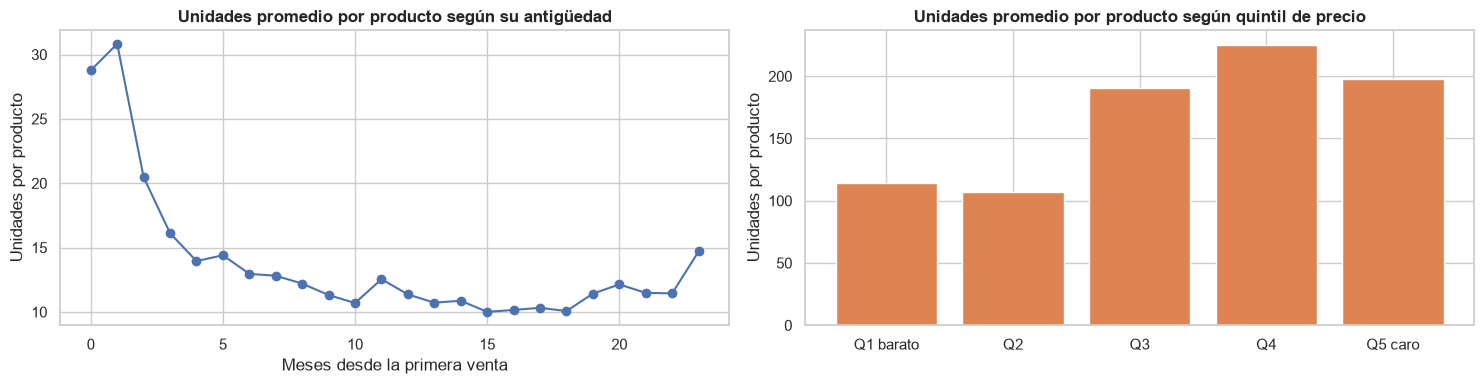

In [39]:
item_first = df.groupby("item_id")["date_block_num"].min()
df["item_age"] = df["date_block_num"] - df["item_id"].map(item_first)
age_curve = df.groupby("item_age")["item_cnt_day"].sum() / df.groupby("item_age")["item_id"].nunique()

price_bins = pd.qcut(df.groupby("item_id")["item_price"].median(), 5,
                     labels=["Q1 barato", "Q2", "Q3", "Q4", "Q5 caro"])
units_by_price = df.groupby(df["item_id"].map(price_bins))["item_cnt_day"].sum() / price_bins.value_counts()

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].plot(age_curve.index[:24], age_curve.values[:24], marker="o")
axes[0].set(title="Unidades promedio por producto según su antigüedad", xlabel="Meses desde la primera venta",
            ylabel="Unidades por producto")
axes[1].bar(units_by_price.index.astype(str), units_by_price.values, color="#DD8452")
axes[1].set(title="Unidades promedio por producto según quintil de precio", ylabel="Unidades por producto")
plt.tight_layout()
plt.show()

| Variable | Efecto observado | Evidencia |
|---|---|---|
| **Ventas pasadas (lags)** | La más fuerte: alta persistencia mes a mes | ACF/PACF en el rezago 1 (sección 9) |
| **Mes del año / diciembre** | Pico navideño en todas las tiendas y categorías | Secciones 6 y 8.d |
| **Tendencia (tiempo)** | Caída sostenida de unidades | Descomposición, ADF |
| **Categoría / grupo** | Define el volumen, el precio y la tendencia propia (formatos físicos en declive) | Secciones 5.b.i y 8.d |
| **Tienda / ciudad** | Gran diferencia de escala entre tiendas; Moscú domina | Secciones 5.b.ii, 7.b y 8.b |
| **Antigüedad del producto** | Las ventas se concentran en los primeros meses tras el lanzamiento y luego decaen | Gráfica anterior |
| **Precio** | Relación no lineal: los productos de precio medio-alto (Q3–Q5) venden en promedio ~2× más unidades por producto que los más baratos (Q1–Q2, donde están libros y música de catálogo). El precio interactúa con la categoría | Gráfica anterior y sección 5 |
| **Tipo de tienda** | La tienda online y la digital (12, 55) tienen ventas masivas | Sección 7.c |

### 10.b Patrones útiles para el forecasting y cobertura de test

,valor
Pares de test,"214,200.00"
Tiendas en test,42.00
Productos en test,"5,100.00"
% pares con historial (tienda-producto ya vendido),52.04
% pares con producto conocido pero nuevo en esa tienda,40.84
% pares con producto totalmente nuevo,7.12
% tiendas de test con historial,100.00
% pares vendidos en oct-2015 (mes 33),13.39


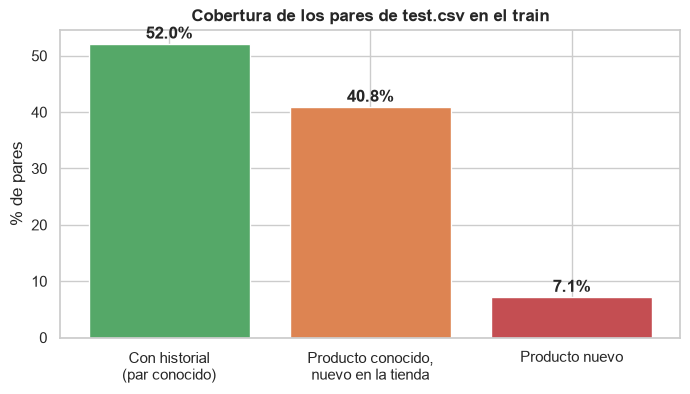

In [40]:
train_pairs = set(zip(df["shop_id"], df["item_id"]))
test_pairs = list(zip(test["shop_id"], test["item_id"]))
has_pair = np.array([p in train_pairs for p in test_pairs])
has_item = test["item_id"].isin(set(df["item_id"])).values
has_shop = test["shop_id"].isin(set(df["shop_id"])).values
last_month_pairs = set(zip(df.loc[df["date_block_num"] == 33, "shop_id"],
                           df.loc[df["date_block_num"] == 33, "item_id"]))
sold_oct = np.array([p in last_month_pairs for p in test_pairs])

coverage = pd.Series({
    "Pares de test": len(test),
    "Tiendas en test": test["shop_id"].nunique(),
    "Productos en test": test["item_id"].nunique(),
    "% pares con historial (tienda-producto ya vendido)": has_pair.mean() * 100,
    "% pares con producto conocido pero nuevo en esa tienda": (has_item & ~has_pair).mean() * 100,
    "% pares con producto totalmente nuevo": (~has_item).mean() * 100,
    "% tiendas de test con historial": has_shop.mean() * 100,
    "% pares vendidos en oct-2015 (mes 33)": sold_oct.mean() * 100,
})
display(coverage.to_frame("valor"))

fig, ax = plt.subplots(figsize=(8, 4))
parts = pd.Series({"Con historial\n(par conocido)": has_pair.mean(),
                   "Producto conocido,\nnuevo en la tienda": (has_item & ~has_pair).mean(),
                   "Producto nuevo": (~has_item).mean()})
ax.bar(parts.index, parts.values * 100, color=["#55A868", "#DD8452", "#C44E52"])
ax.set(title="Cobertura de los pares de test.csv en el train", ylabel="% de pares")
for i, v in enumerate(parts.values * 100):
    ax.text(i, v + 1, f"{v:.1f}%", ha="center", fontweight="bold")
plt.show()

**Cobertura de test**
- Solo **~52 %** de los pares tienda-producto de `test.csv` tienen historial de ventas en el train.
- **~41 %** son productos conocidos que nunca se vendieron en esa tienda.
- **~7 %** son **productos completamente nuevos** (363 productos sin ninguna venta histórica).
- Las 42 tiendas de test tienen historial; la tienda `36` tiene solo un mes.
- Apenas **~13 %** de los pares de test tuvo venta en octubre 2015.

**Patrones útiles para el forecasting**
1. **Construir el train como malla completa:** `test` es el producto cartesiano de 42 tiendas × 5,100 productos, así que la mayoría de los objetivos serán **0**. Para que el modelo aprenda esos ceros, el set de entrenamiento debe construirse igual: para cada mes, todas las combinaciones de tiendas y productos activos, rellenando con 0.
2. **Variables de rezago** (`lag_1`, `lag_2`, `lag_3`, `lag_12`) a nivel par, producto, tienda y categoría, y medias móviles.
3. **Estacionalidad:** mes del año. Noviembre suele superar ligeramente a octubre, en la antesala de diciembre.
4. **Tendencia:** `date_block_num` como variable, o normalizar por la tendencia.
5. **Productos nuevos y pares sin historial (~48 %):** usar variables "de respaldo" como el promedio de la **categoría**, de la **tienda**, del producto en *otras* tiendas, el **precio** y texto del nombre (plataforma: PS4, PC, etc.).
6. **Recortar el objetivo a [0, 20]**, como hace Kaggle, para reducir el impacto de las ventas masivas.

### 10.c Calidad y preparación del dataset

**Calidad general: alta.**
- No hay valores nulos.
- Las fechas tienen un formato consistente y `date_block_num` es 100 % coherente con ellas.
- Hay muy pocos duplicados (6) y muy pocos valores inválidos (1 precio negativo y 2 outliers extremos).

**Problemas encontrados y resueltos**
- Tiendas duplicadas con distinto ID (0→57, 1→58, 11→10), ya unificadas.
- Devoluciones (cantidades negativas), conservadas porque el objetivo es neto.
- Outliers extremos, eliminados con umbrales justificados. Las ventas masivas legítimas se conservan.
- Los nombres en ruso se tradujeron a grupos de categoría en español para el análisis.

**Retos para las siguientes etapas**
- **Dispersión extrema:** la mayoría de las series tienda-producto son intermitentes (muchos ceros).
- **Cambio en el universo:** tiendas que abren y cierran, y productos que entran y salen del catálogo; el ~48 % de los pares de test no tiene historial.
- **Tendencia descendente y cambio de mix** (de formatos físicos a digitales y consolas nuevas): un modelo que solo promedie el pasado sobrestimará las ventas.
- **Pocas observaciones temporales** (34 meses) para estimar la estacionalidad anual.

**Preparación:** el dataset limpio está guardado en `data/interim/sales_clean.parquet`. El siguiente paso (feature engineering) es construir la malla mensual tienda × producto, agregar `item_cnt_month`, recortarlo a [0, 20] y generar las variables de rezago, calendario, categoría, tienda y precio identificadas en este EDA.